# Top-10 candidate analyses

Everything in this notebook is restricted to the **ten paper-confirmed candidates** in
`data/proteomes/10_top_candidates/`, scored with the **scaled combined-dataset GNN**
(`checkpoints/gnn/gnn_scaled_combined_dataset/`). The companion notebooks
`mutation_analysis.ipynb` and `length_cutoff_analysis.ipynb` cover the full 1,074-candidate
short list under the same checkpoint.

Three runs are covered, all from that checkpoint and all **pinned by run id** in the loader
cell rather than taken as newest-on-disk: **mutation robustness**, **deletion** and
**insertion**, i.e. extension back into the native flanks. Further analyses over the same ten
get their own sections as those runs land.

## Mutation robustness

Inputs (CSV file contracts, no module imports):

- `mutation_curves.csv` — one row per (parent, scheme, p): retention, mean P(AMP), mean σ
- `mutation_robustness.csv` — one row per (parent, scheme): parent baseline and collapsed scores

Two model outputs are used throughout, named consistently:

- **σ (sigma score)** — the **raw logit difference**, `logit_AMP − logit_nonAMP`, straight from the
  GNN head. Unbounded, signed.
- **P(AMP)** — the calibrated probability. These runs used `fitting = "temperature"`, so
  P(AMP) = `sigmoid(σ / T)` and P ≥ 0.5 and σ > 0 select exactly the same peptides. Only Platt
  scaling carries an intercept and so would move the 0.5 crossing off σ = 0; `SIGMA_THRESHOLD`
  is derived from the run's own calibration rather than assumed, and the loader cell prints
  both it and T.

**Panels plot absolute σ and P(AMP), not Δ.** A Δ curve shows how far a peptide fell but not
where it started, which is the quantity that decides whether a perturbed variant is still called
an AMP. Every curve therefore carries its unperturbed parent score as its own **p = 0** (or
fraction-0) point, and the AMP threshold is drawn on the same axis. Δ columns are still derived
where a section needs them — the overall ranking table below reports both.

The backbone is **fixed** for mutation: every mutant is scored on its parent's ESMFold structure
from `generated/structures/`, so what is measured is the model's sensitivity to sequence identity
at fixed geometry, not a refolding experiment.

In [25]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Recorded runs, all on checkpoints/gnn/gnn_scaled_combined_dataset with
# --fitting temperature. Pinned rather than taken as newest-on-disk, so the panels
# always describe one set of prediction runs; set an entry to None to fall back to
# the newest run holding that file.
RUN_IDS = {
    "mutation_curves.csv": "gnn-scaled-mutation-2026-11-18_11-08",
    "mutation_robustness.csv": "gnn-scaled-mutation-2026-11-18_11-08",
    "length_deletion_curves.csv": "gnn-scaled-deletion-2026-11-18_11-17",
    "length_deletion_robustness.csv": "gnn-scaled-deletion-2026-11-18_11-17",
    "length_predictions.csv": "gnn-scaled-insertion-2026-11-18_11-17_02",
}


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "mutation_analysis").is_dir():
            return path
    raise FileNotFoundError("Could not locate the repository root.")


def run_csv(data_root: Path, filename: str) -> Path:
    results_root = data_root / "results"
    run_id = RUN_IDS.get(filename)
    if run_id is not None:
        return results_root / "runs" / run_id / filename
    candidates = list((results_root / "runs").glob(f"*/{filename}"))
    if not candidates:
        return results_root / filename
    return max(candidates, key=lambda path: path.stat().st_mtime_ns)


ROOT = find_repo_root()
DATA_ROOT = ROOT / "data" / "proteomes" / "10_top_candidates"
CURVES_CSV = run_csv(DATA_ROOT, "mutation_curves.csv")
ROBUSTNESS_CSV = run_csv(DATA_ROOT, "mutation_robustness.csv")

SCHEME_ORDER = ["physicochemical", "blosum62", "uniform"]
SCHEME_LABEL = {
    "physicochemical": "Physicochemical-preserving",
    "blosum62": "BLOSUM62-softmax",
    "uniform": "Uniform random",
}
SCHEME_COLOR = {"physicochemical": "#2a78d6", "blosum62": "#eb6834", "uniform": "#1baf7a"}
SCHEME_MARKER = {"physicochemical": "o", "blosum62": "s", "uniform": "^"}

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "monospace"
# TrueType (Type 42) so PDF text stays editable vectors instead of raster outlines.
plt.rcParams["pdf.fonttype"] = 42

SPINE_COLOR = "#2b2b2b"
LABEL_SIZE = 10.5
TITLE_SIZE = 12


def style_axes(ax, grid_axis: str = "y") -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(SPINE_COLOR)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.grid(axis=grid_axis, linestyle="--", linewidth=0.6, alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)


def ladder_heights(values, minimum_gap: float) -> list[float]:
    """Monotone label positions: each sits at its value or one gap above the last."""
    heights, previous = [], -np.inf
    for value in values:
        previous = max(float(value), previous + minimum_gap)
        heights.append(previous)
    return heights


def with_original(frame: pd.DataFrame, columns: dict, keys: list[str]) -> pd.DataFrame:
    """Prepend a p = 0 row per group carrying the unperturbed parent's own score.

    ``columns`` maps each variant column to the parent column it starts from, or to a
    constant where no parent column exists. The sweep CSVs begin at the first
    perturbed level, so without this an absolute panel shows how far a peptide fell
    but not where it started.
    """
    keep = [*keys, "p", *columns]
    start = frame.drop_duplicates(keys).copy()
    start["p"] = 0.0
    for value, origin in columns.items():
        start[value] = start[origin] if isinstance(origin, str) else origin
    return pd.concat([start[keep], frame[keep]], ignore_index=True)


# Which run, which checkpoint, which calibration - printed rather than assumed, so a
# later run against a different checkpoint cannot be read as this one.
manifest = json.loads((CURVES_CSV.parent / "run_manifest.json").read_text())
checkpoint_dir = Path(manifest["model"]["files"]["checkpoint_dir"]["path"])
if not checkpoint_dir.is_dir():
    checkpoint_dir = ROOT / "checkpoints" / "gnn" / checkpoint_dir.name
temperature_file = checkpoint_dir / "gnn_temperature_scaling"
TEMPERATURE = json.loads(temperature_file.read_text())["temperature"] if temperature_file.is_file() else None

# Only Platt scaling carries an intercept, so it is the only calibration whose
# P(AMP) = 0.5 crossing moves off sigma = 0 (gnn_minimal/core/calibration.py).
FITTING = manifest["config"]["effective"]["fitting"]
if FITTING == "platt":
    platt = json.loads((checkpoint_dir / "gnn_platt_scaling").read_text())
    SIGMA_THRESHOLD = -float(platt["intercept"]) / float(platt["coef"])
else:
    SIGMA_THRESHOLD = 0.0

print("Run:        ", manifest["run_id"], f"({manifest['status']})")
print("Checkpoint: ", checkpoint_dir.name)
print("Fitting:    ", FITTING, f"T = {TEMPERATURE:.5f}" if TEMPERATURE else "")
print("AMP call at  sigma >", f"{SIGMA_THRESHOLD:.3f}", " / P(AMP) >= 0.5")
print("Structures: ", manifest["config"]["effective"]["parent_structures_used"])
print("Curves:     ", CURVES_CSV)
print("Robustness: ", ROBUSTNESS_CSV)

Run:         2026-11-18_11-08 (completed)
Checkpoint:  gnn_scaled_combined_dataset
Fitting:     temperature T = 0.55893
AMP call at  sigma > 0.000  / P(AMP) >= 0.5
Structures:  data/proteomes/10_top_candidates/generated/structures
Curves:      /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/10_top_candidates/results/runs/gnn-scaled-mutation-2026-11-18_11-08/mutation_curves.csv
Robustness:  /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/10_top_candidates/results/runs/gnn-scaled-mutation-2026-11-18_11-08/mutation_robustness.csv


In [26]:
curves = pd.read_csv(CURVES_CSV)
robustness = pd.read_csv(ROBUSTNESS_CSV)

# Project vocabulary is sigma, not margin. The source CSVs still carry the
# margin_* / logit_margin names written by mutation_analysis.
SIGMA_RENAMES = {
    "parent_logit_margin": "parent_sigma",
    "margin_auc": "mutation_sigma_auc",
    "margin_slope": "sigma_slope",
    "mean_logit_margin": "mean_sigma",
    "sd_logit_margin": "sd_sigma",
    "logit_margin": "sigma",
}
curves = curves.rename(columns=SIGMA_RENAMES)
robustness = robustness.rename(columns=SIGMA_RENAMES)

PARENT_COLUMNS = ["parent_id", "sequence", "length", "parent_pred", "parent_prob_AMP", "parent_sigma"]
parents = robustness[PARENT_COLUMNS].drop_duplicates("parent_id")

curves = curves.merge(parents, on="parent_id", how="left")
curves["delta_sigma"] = curves["mean_sigma"] - curves["parent_sigma"]
curves["delta_prob_AMP"] = curves["mean_delta_prob_AMP"]

# Worst-scheme score per peptide, so none looks robust merely because
# physicochemical substitution barely perturbed it.
worst = robustness.loc[robustness.groupby("parent_id")["mutation_sigma_auc"].idxmin()].copy()
worst["mutation_sigma_retained"] = worst["mutation_sigma_auc"] / worst["parent_sigma"]
worst = worst.sort_values("mutation_sigma_auc", ascending=False).reset_index(drop=True)
worst["rank"] = np.arange(1, len(worst) + 1)

# One colour per peptide, fixed by that ranking and reused on every panel below.
PEPTIDE_ORDER = worst["parent_id"].tolist()
PEPTIDE_COLOR = dict(zip(PEPTIDE_ORDER, plt.get_cmap("tab10").colors))

P_LEVELS = sorted(curves["p"].unique())
# p = 0 is the unmutated peptide, carried onto every absolute curve below.
P_LEVELS_FROM_ORIGINAL = [0.0, *P_LEVELS]
not_amp = parents.loc[parents["parent_sigma"] <= 0, "parent_id"].tolist()

print(f"peptides:    {len(parents)}   sigma > 0: {len(parents) - len(not_amp)}"
      + (f"   NOT called AMP: {not_amp}" if not_amp else ""))
print(f"curve rows:  {len(curves)}   ({len(SCHEME_ORDER)} schemes x {len(P_LEVELS)} p levels)")
print(f"lengths:     {parents['length'].min()}-{parents['length'].max()} aa")
print(f"replicates per cell: {int(curves['n_variants'].iloc[0])}")

peptides:    10   sigma > 0: 10
curve rows:  270   (3 schemes x 9 p levels)
lengths:     11-37 aa
replicates per cell: 500


### The candidate set

All ten peptides, ranked by **`mutation_sigma_auc`** — the mean σ sustained across the sweep under
the peptide's **worst** scheme, so none can look robust merely because physicochemical
substitution barely perturbed it. `mutation_sigma_retained = mutation_sigma_auc / parent_sigma` is
the fraction of unmutated σ still held.

The last three columns are `retention_auc` per scheme: the area under the retention-versus-p curve,
i.e. the fraction of the 500 replicates per cell still called AMP, averaged over the nine doses.

No percentile-rank blend is used here (the 1,074-candidate notebook's `combined_score`): over ten
peptides a percentile rank moves in steps of 0.1, which is too coarse to carry a ranking.

In [27]:
overview = parents.merge(
    worst[["parent_id", "rank", "scheme", "mutation_sigma_auc", "mutation_sigma_retained"]],
    on="parent_id", how="left",
).rename(columns={"scheme": "worst_scheme"})
retention_by_scheme = robustness.pivot(index="parent_id", columns="scheme", values="retention_auc")
overview = overview.merge(retention_by_scheme[SCHEME_ORDER], on="parent_id", how="left")
overview = overview.sort_values("rank")

OVERVIEW_COLUMNS = (["rank", "parent_id", "sequence", "length", "parent_sigma", "parent_prob_AMP",
                     "mutation_sigma_auc", "mutation_sigma_retained", "worst_scheme"] + SCHEME_ORDER)
display(overview[OVERVIEW_COLUMNS].style.format({
    "parent_sigma": "{:.3f}", "parent_prob_AMP": "{:.3f}", "mutation_sigma_auc": "{:.3f}",
    "mutation_sigma_retained": "{:.3f}", "physicochemical": "{:.3f}", "blosum62": "{:.3f}",
    "uniform": "{:.3f}",
}).hide(axis="index"))

rank,parent_id,sequence,length,parent_sigma,parent_prob_AMP,mutation_sigma_auc,mutation_sigma_retained,worst_scheme,physicochemical,blosum62,uniform
1,RPL41,MRAKWRKKRMRRLK,14,2.744,0.993,1.689,0.615,uniform,1.000,0.968,0.918
2,DCTN4,SQLYPRHKHLLIKRSLRCRKC,21,2.895,0.994,1.490,0.515,uniform,1.000,0.940,0.893
3,RPS29,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGLNM,37,2.045,0.975,0.874,0.427,blosum62,1.000,0.828,0.838
4,CHMP2A,RRYVRKFVLMR,11,2.050,0.975,0.498,0.243,uniform,0.986,0.828,0.641
5,PPP1CB,KRRFNIKLWKTF,12,1.900,0.968,0.408,0.215,uniform,0.979,0.725,0.602
6,PSMG2,RSIFIKYKSKPFCEKLLSWVKS,22,1.431,0.928,0.134,0.094,uniform,0.940,0.610,0.524
7,RPS4X,LPLIIFLRNRLKY,13,0.674,0.769,-0.023,-0.035,uniform,0.723,0.528,0.467
8,ETS1,SRGLRYYYDKNIIHKTAGKRYVYRFV,26,0.683,0.773,-0.035,-0.051,uniform,0.968,0.579,0.471
9,DFNA5,SLVTKKKRFWCWQRPKYQFL,20,0.180,0.580,-0.139,-0.771,uniform,0.713,0.451,0.415
10,GLB1,SRVPRFYWKDRLLKMKMA,18,0.386,0.666,-0.228,-0.592,uniform,0.920,0.499,0.414


### Absolute σ and P(AMP) versus p

One panel per mutation scheme, one line per peptide, coloured consistently across every figure
below and labelled at p = 0.5. The bold black line is the unweighted mean over the ten, annotated
at both ends, and the dashed line is the AMP threshold.

Each line starts at **p = 0**, the peptide's own unmutated score, so the panel shows where each
candidate began and how close to the threshold its mutants end up — not only how far they moved.

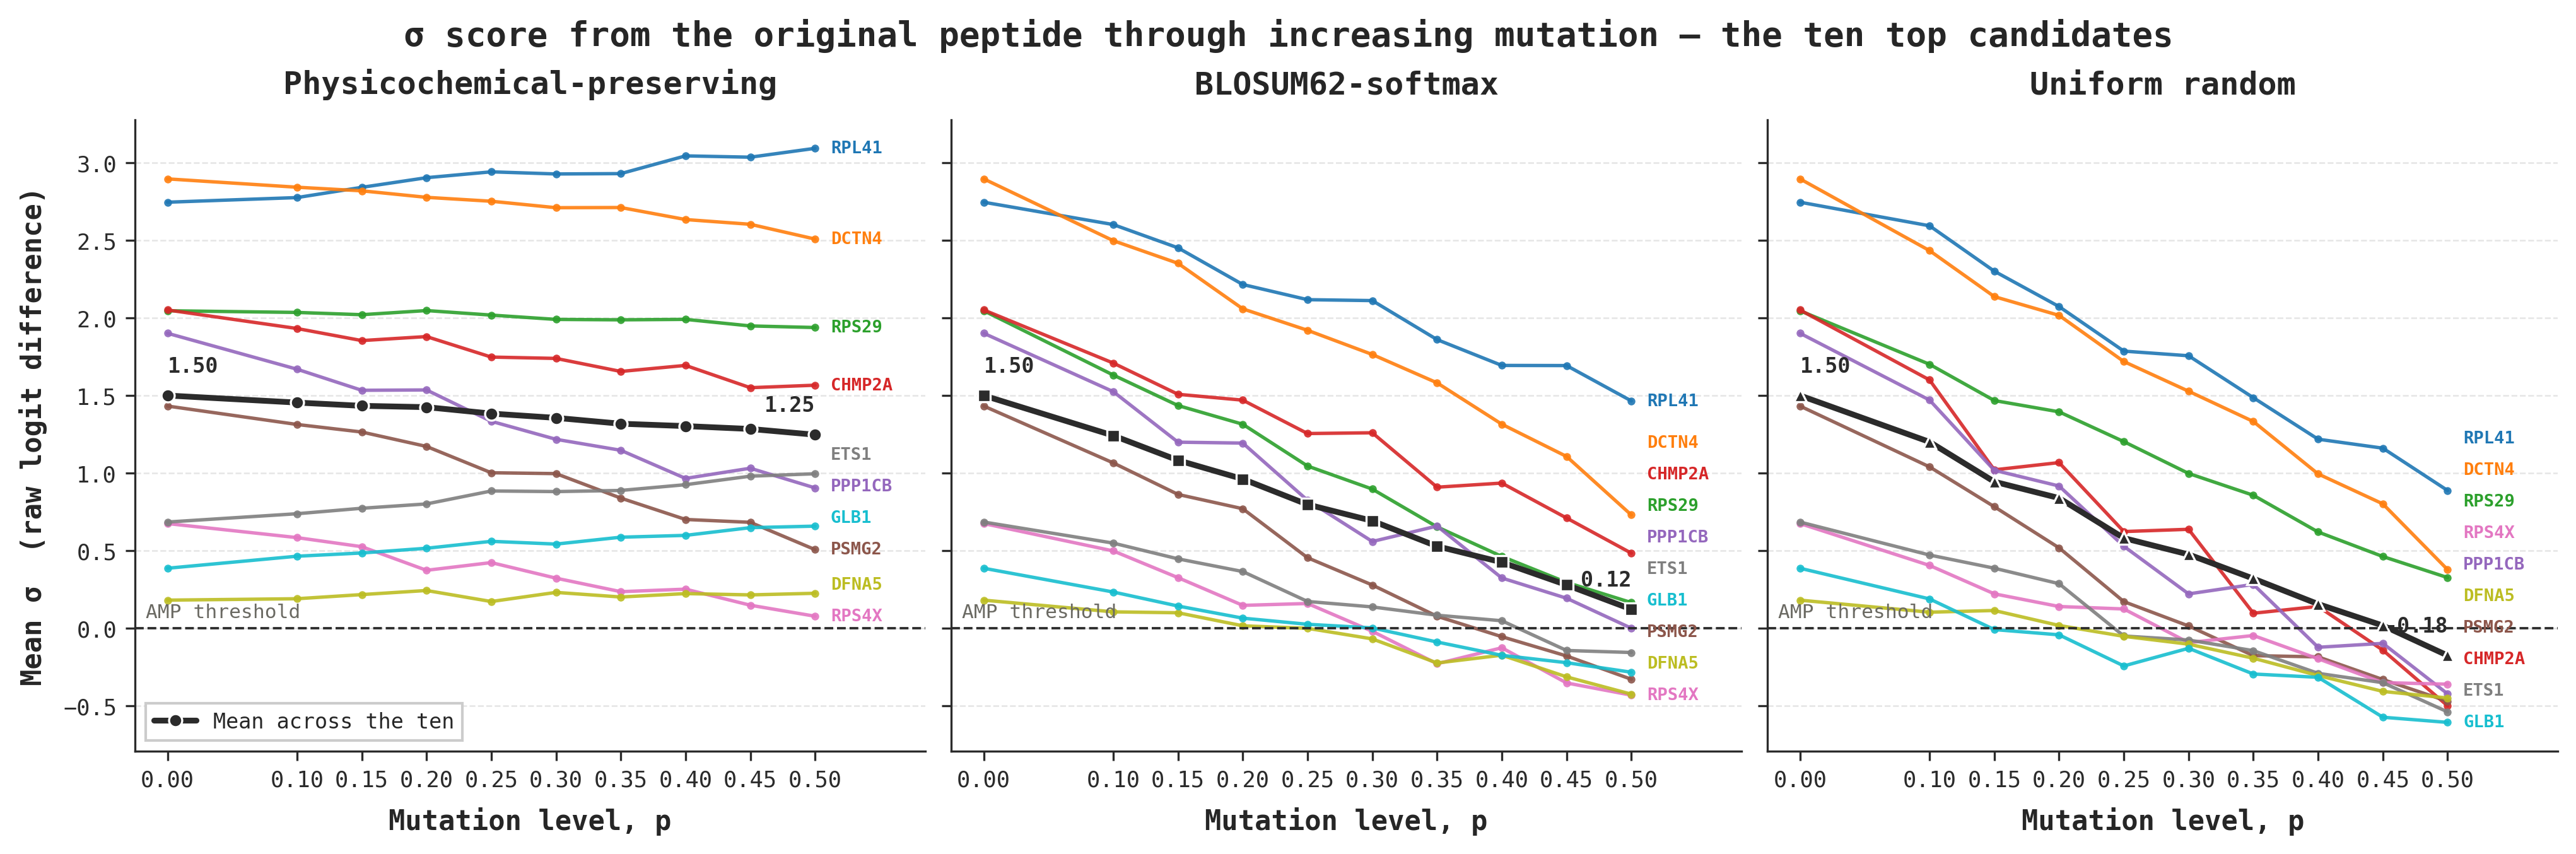

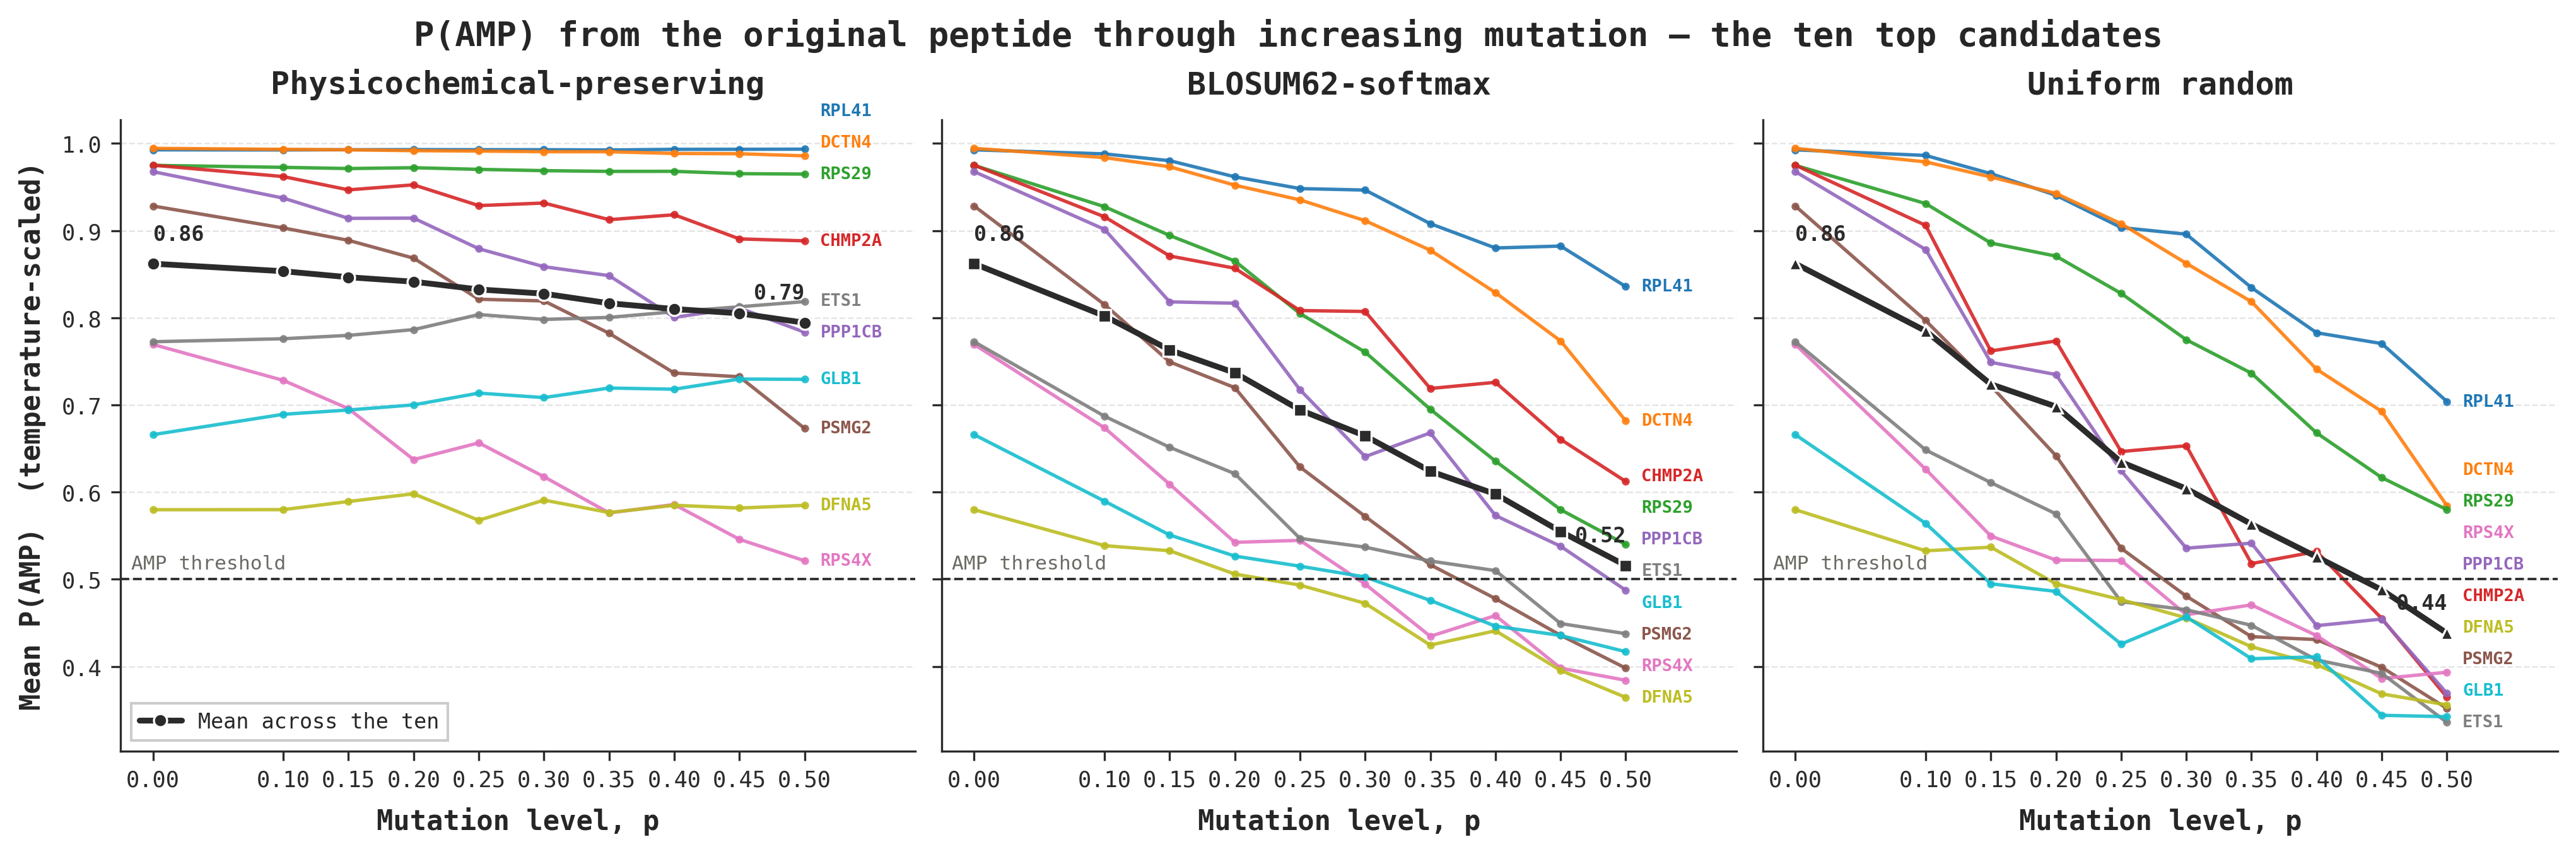

In [28]:
def plot_score_vs_p(value: str, parent_value: str, threshold: float,
                    y_label: str, title: str) -> None:
    """Absolute score against p, each peptide starting at its own unmutated score."""
    anchored = with_original(curves, {value: parent_value}, ["parent_id", "scheme"])
    figure, axes = plt.subplots(1, len(SCHEME_ORDER), figsize=(13.5, 4.4), dpi=300,
                                sharey=True, layout="constrained")
    low, high = anchored[value].min(), anchored[value].max()
    gap = (high - low) * 0.055

    for axis, scheme in zip(axes, SCHEME_ORDER):
        subset = anchored[anchored["scheme"] == scheme]
        lines = subset.pivot(index="p", columns="parent_id", values=value)[PEPTIDE_ORDER]
        for peptide in PEPTIDE_ORDER:
            axis.plot(lines.index, lines[peptide], color=PEPTIDE_COLOR[peptide],
                      linewidth=1.3, marker="o", markersize=3, markeredgewidth=0, alpha=0.9)

        ends = lines.iloc[-1].sort_values()
        for peptide, height in zip(ends.index, ladder_heights(ends.to_numpy(), gap)):
            axis.annotate(peptide, xy=(P_LEVELS[-1], ends[peptide]),
                          xytext=(P_LEVELS[-1] + 0.012, height), fontsize=6.5,
                          fontweight="bold", color=PEPTIDE_COLOR[peptide], va="center",
                          annotation_clip=False)

        mean = subset.groupby("p")[value].mean()
        axis.plot(mean.index, mean.to_numpy(), color=SPINE_COLOR, linewidth=2.2,
                  marker=SCHEME_MARKER[scheme], markersize=5, markeredgecolor="white",
                  markeredgewidth=0.8, zorder=5, label="Mean across the ten")
        # The original and final means, so the absolute drop is readable off the panel.
        for index, align in ((0, "left"), (-1, "right")):
            axis.annotate(f"{mean.iloc[index]:.2f}", (mean.index[index], mean.iloc[index]),
                          textcoords="offset points", xytext=(0, 9), ha=align,
                          fontsize=8, fontweight="bold", color=SPINE_COLOR, zorder=6)

        axis.axhline(threshold, color=SPINE_COLOR, linewidth=0.9, linestyle="--")
        axis.annotate("AMP threshold", xy=(0.0, threshold), xycoords=("axes fraction", "data"),
                      textcoords="offset points", xytext=(4, 4), fontsize=7.5, color="#6b6a63")
        axis.set_title(SCHEME_LABEL[scheme], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
        axis.set_xlabel("Mutation level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
        axis.set_xticks(P_LEVELS_FROM_ORIGINAL)
        axis.set_xlim(right=P_LEVELS[-1] + 0.085)
        style_axes(axis)

    axes[0].set_ylabel(y_label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    axes[0].legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
    figure.suptitle(title, fontsize=TITLE_SIZE + 1, fontweight="bold")
    plt.show()


plot_score_vs_p(
    "mean_sigma", "parent_sigma", SIGMA_THRESHOLD,
    "Mean σ  (raw logit difference)",
    "σ score from the original peptide through increasing mutation — the ten top candidates",
)
plot_score_vs_p(
    "mean_prob_AMP", "parent_prob_AMP", 0.5,
    "Mean P(AMP)  (temperature-scaled)",
    "P(AMP) from the original peptide through increasing mutation — the ten top candidates",
)

### Retention versus p — scheme comparison

`retention` is the fraction of the 500 replicates in a cell still called AMP, so this is a survival
curve against mutation dose. The claim it tests: conservative substitutions should degrade the call
more slowly than uniform random ones. Bands are normal-approximation 95% CIs over the ten peptides.

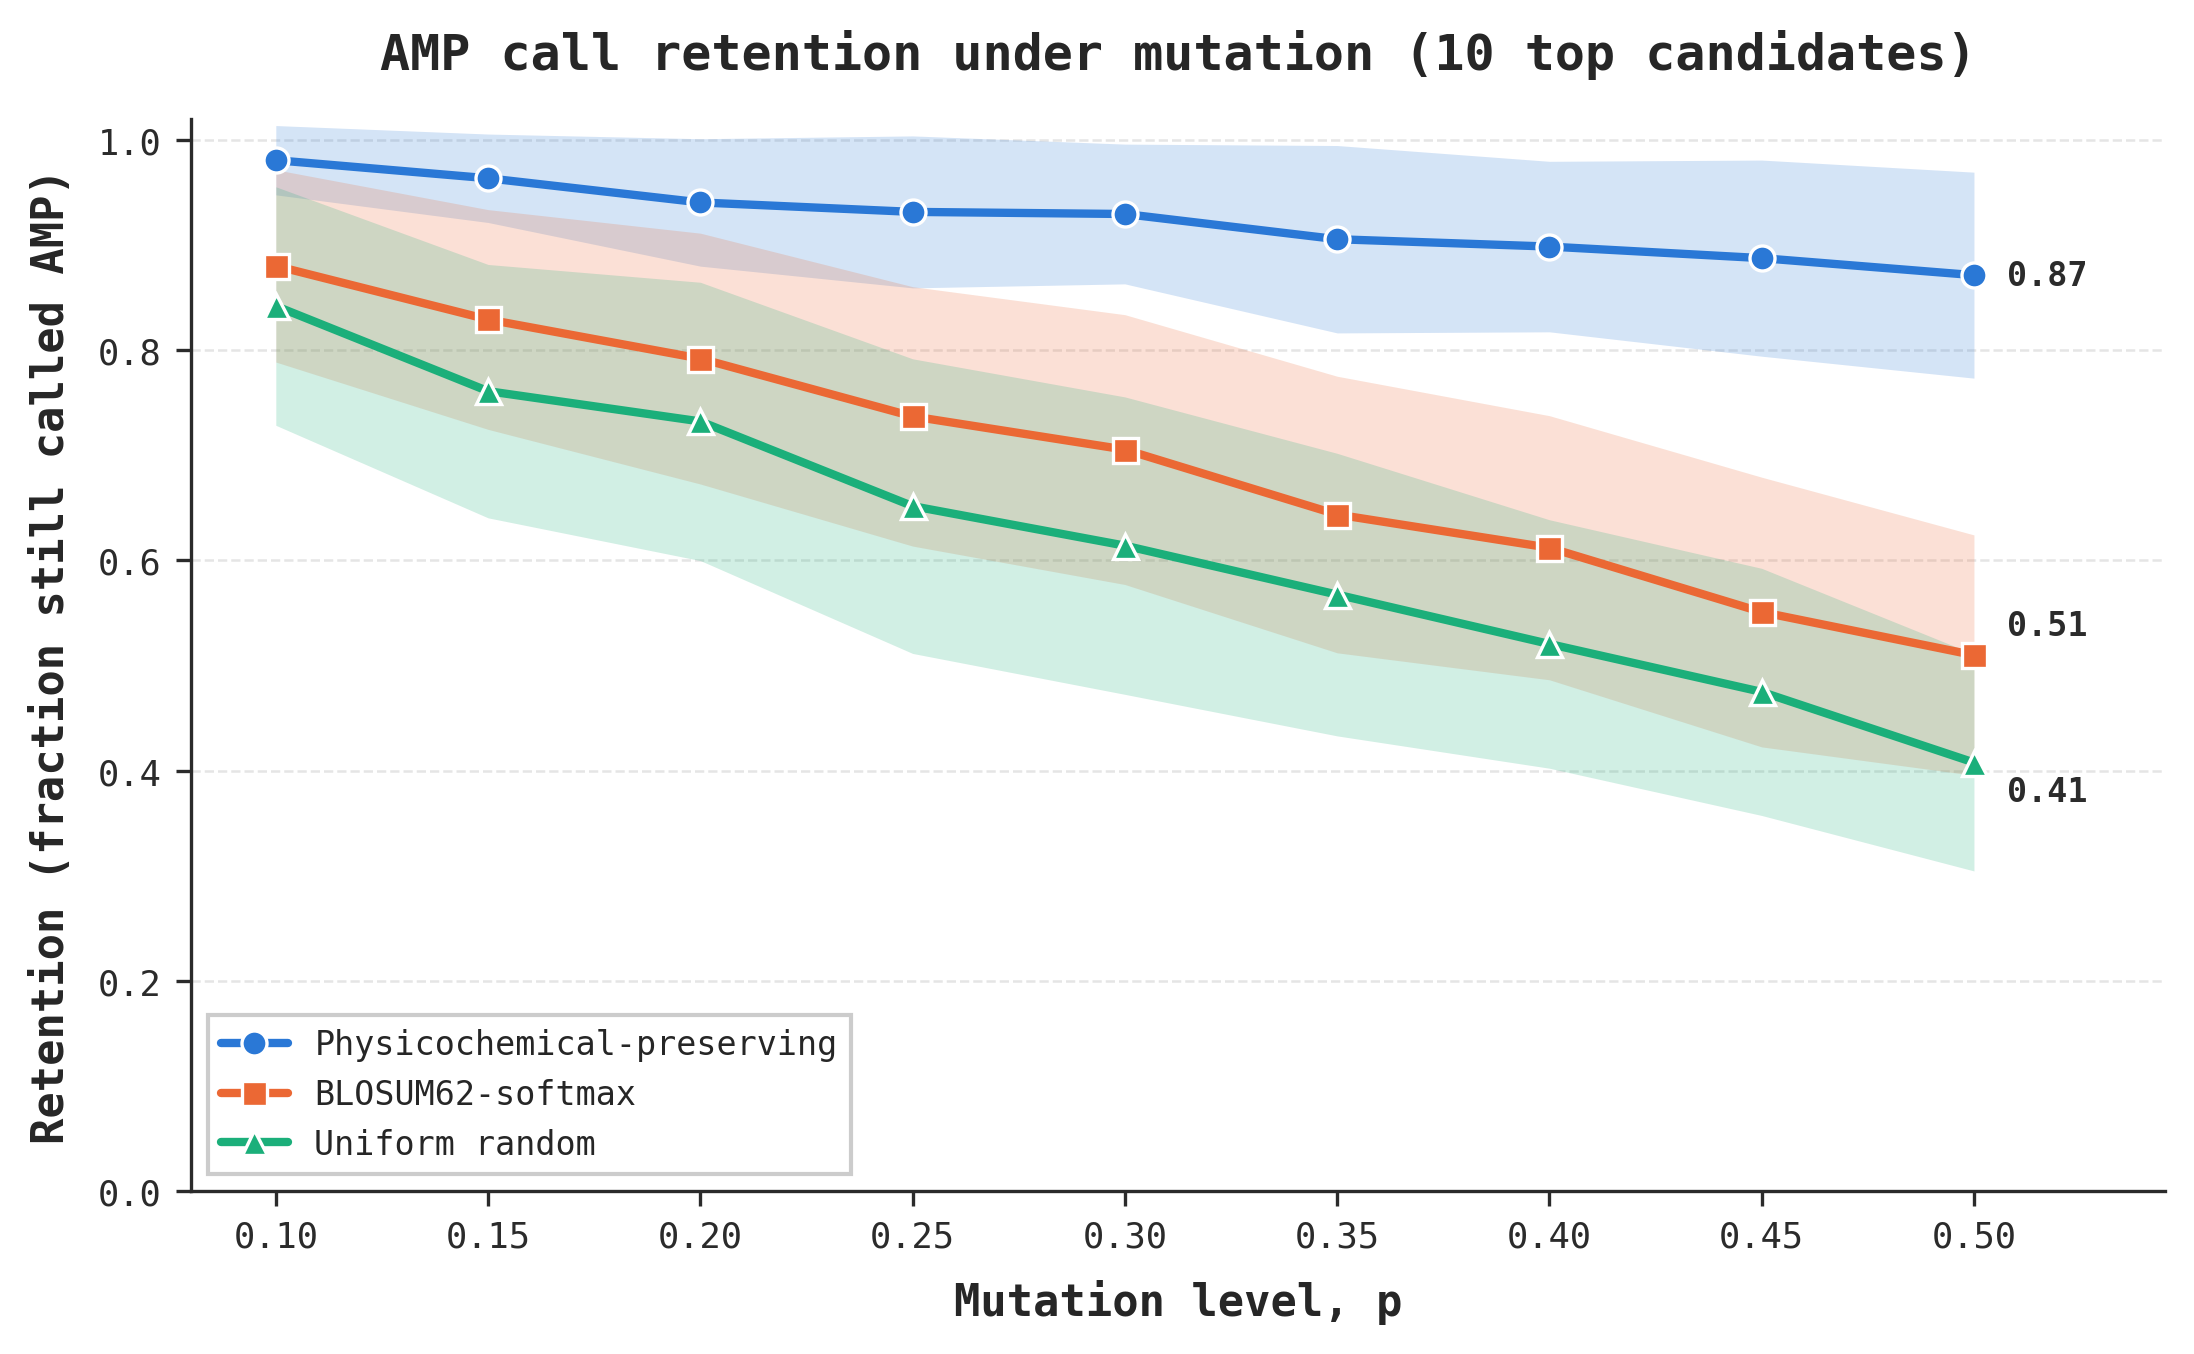

In [29]:
def mean_ci(frame: pd.DataFrame, value: str) -> pd.DataFrame:
    """Per-p mean across peptides with a normal-approximation 95% CI."""
    stats = frame.groupby("p")[value].agg(["mean", "std", "count"])
    half_width = 1.96 * stats["std"] / np.sqrt(stats["count"])
    stats["low"] = stats["mean"] - half_width
    stats["high"] = stats["mean"] + half_width
    return stats.reset_index()


LABEL_OFFSET = {"physicochemical": 0.0, "blosum62": 7.0, "uniform": -7.0}

figure, axis = plt.subplots(figsize=(7.2, 4.4), dpi=300, layout="constrained")
for scheme in SCHEME_ORDER:
    stats = mean_ci(curves[curves["scheme"] == scheme], "retention")
    color = SCHEME_COLOR[scheme]
    axis.fill_between(stats["p"], stats["low"], stats["high"], color=color, alpha=0.2, linewidth=0)
    axis.plot(stats["p"], stats["mean"], color=color, linewidth=2.0,
              marker=SCHEME_MARKER[scheme], markersize=6, markeredgecolor="white",
              markeredgewidth=0.8, label=SCHEME_LABEL[scheme])
    axis.annotate(f"{stats['mean'].iloc[-1]:.2f}", (stats["p"].iloc[-1], stats["mean"].iloc[-1]),
                  textcoords="offset points", xytext=(8, LABEL_OFFSET[scheme]),
                  color=SPINE_COLOR, fontsize=8, fontweight="bold", va="center")

axis.set_xlabel("Mutation level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_ylabel("Retention (fraction still called AMP)", fontsize=LABEL_SIZE,
                fontweight="bold", labelpad=6)
axis.set_xticks(P_LEVELS)
axis.set_xlim(right=0.545)
axis.set_ylim(0, 1.02)
axis.legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
axis.set_title(f"AMP call retention under mutation ({len(parents)} top candidates)",
               fontsize=TITLE_SIZE, fontweight="bold", pad=12)
style_axes(axis)
plt.show()

### Per-peptide retention

The same curves split per peptide, which is what the ten-peptide set makes possible — the mean
above hides that the schemes separate for some candidates and collapse onto each other for others.
Panels are ordered by sustained σ, and the title carries each peptide's length and unmutated σ.

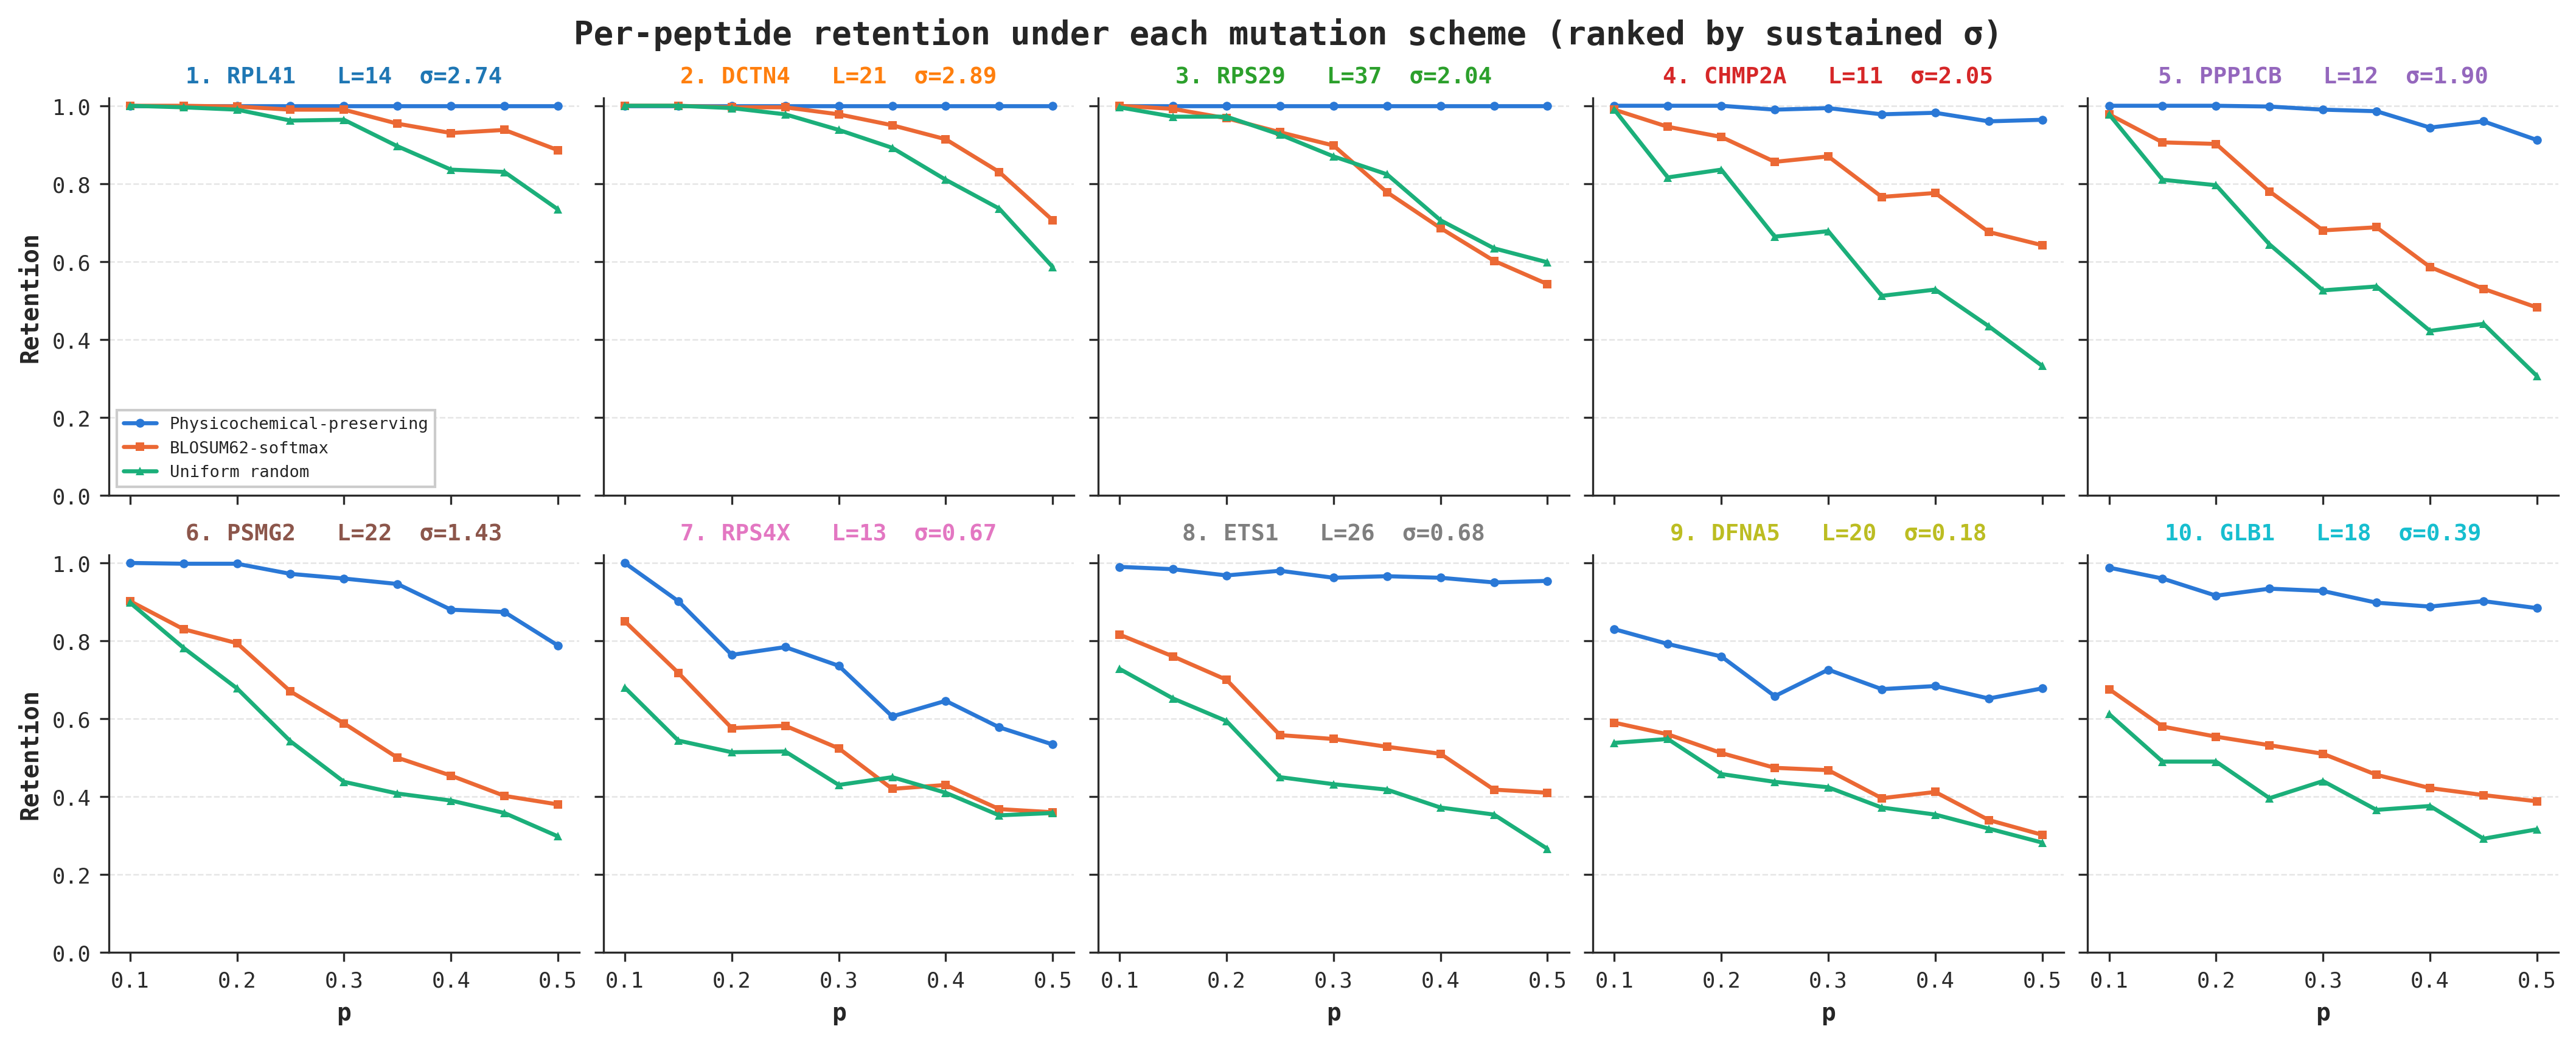

In [30]:
figure, axes = plt.subplots(2, 5, figsize=(14.0, 5.6), dpi=300, sharex=True, sharey=True,
                            layout="constrained")
for axis, peptide in zip(axes.flat, PEPTIDE_ORDER):
    subset = curves[curves["parent_id"] == peptide]
    for scheme in SCHEME_ORDER:
        cell = subset[subset["scheme"] == scheme]
        axis.plot(cell["p"], cell["retention"], color=SCHEME_COLOR[scheme], linewidth=1.6,
                  marker=SCHEME_MARKER[scheme], markersize=3.5, markeredgewidth=0,
                  label=SCHEME_LABEL[scheme])
    row = worst[worst["parent_id"] == peptide].iloc[0]
    axis.set_title(f"{int(row['rank'])}. {peptide}   L={int(row['length'])}  σ={row['parent_sigma']:.2f}",
                   fontsize=9, fontweight="bold", pad=6, color=PEPTIDE_COLOR[peptide])
    axis.set_xticks([0.1, 0.2, 0.3, 0.4, 0.5])
    axis.set_ylim(0, 1.02)
    style_axes(axis)

for axis in axes[1]:
    axis.set_xlabel("p", fontsize=9.5, fontweight="bold", labelpad=4)
for axis in axes[:, 0]:
    axis.set_ylabel("Retention", fontsize=9.5, fontweight="bold", labelpad=4)

axes[0, 0].legend(loc="lower left", fontsize=6.5, frameon=True, fancybox=False, framealpha=1)
figure.suptitle("Per-peptide retention under each mutation scheme (ranked by sustained σ)",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### Retention per peptide and dose

The same numbers as a grid, which makes the dose at which each candidate starts losing its call
directly readable. Rows keep the sustained-σ ranking; columns are the nine nominal mutation levels.

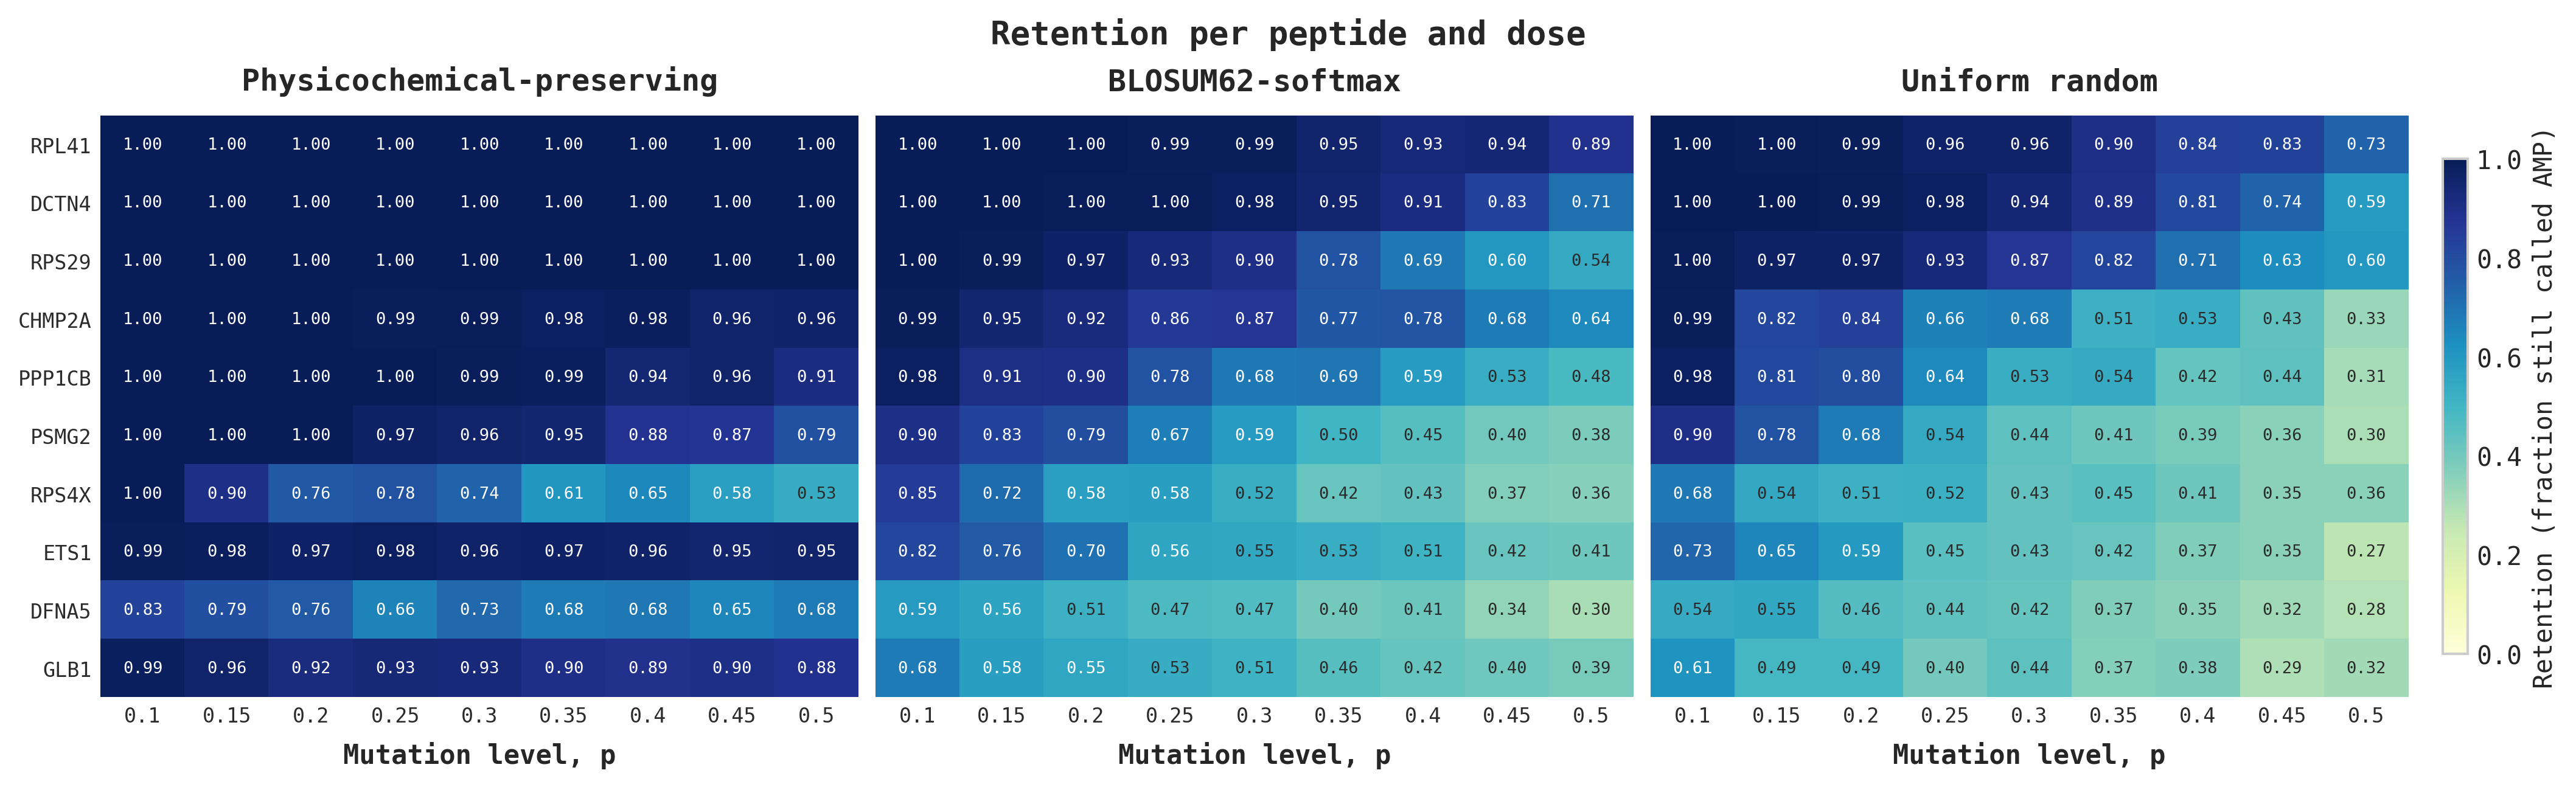

In [31]:
figure, axes = plt.subplots(1, len(SCHEME_ORDER), figsize=(14.0, 4.2), dpi=300,
                            sharey=True, layout="constrained")
for axis, scheme in zip(axes, SCHEME_ORDER):
    grid = (curves[curves["scheme"] == scheme]
            .pivot(index="parent_id", columns="p", values="retention")
            .loc[PEPTIDE_ORDER])
    image = axis.imshow(grid.to_numpy(), cmap="YlGnBu", vmin=0.0, vmax=1.0, aspect="auto")
    for row in range(grid.shape[0]):
        for column in range(grid.shape[1]):
            value = grid.iat[row, column]
            axis.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=6.5,
                      color="white" if value > 0.55 else SPINE_COLOR)
    axis.set_xticks(range(len(P_LEVELS)), [f"{p:g}" for p in P_LEVELS], fontsize=8)
    axis.set_yticks(range(len(PEPTIDE_ORDER)), PEPTIDE_ORDER, fontsize=8)
    axis.set_xlabel("Mutation level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    axis.set_title(SCHEME_LABEL[scheme], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
    axis.grid(False)
    axis.tick_params(length=0, colors=SPINE_COLOR)
    for spine in axis.spines.values():
        spine.set_visible(False)

figure.colorbar(image, ax=axes, shrink=0.85, pad=0.015,
                label="Retention (fraction still called AMP)")
figure.suptitle("Retention per peptide and dose", fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### Potency versus robustness

Orange is the unmutated σ, blue is the mean σ sustained across the sweep under the worst scheme,
and the gap between them is what mutation costs. The percentage is `mutation_sigma_retained`. A
peptide can rank well here either by starting high or by giving up little — the two are separated
by eye rather than collapsed into one score.

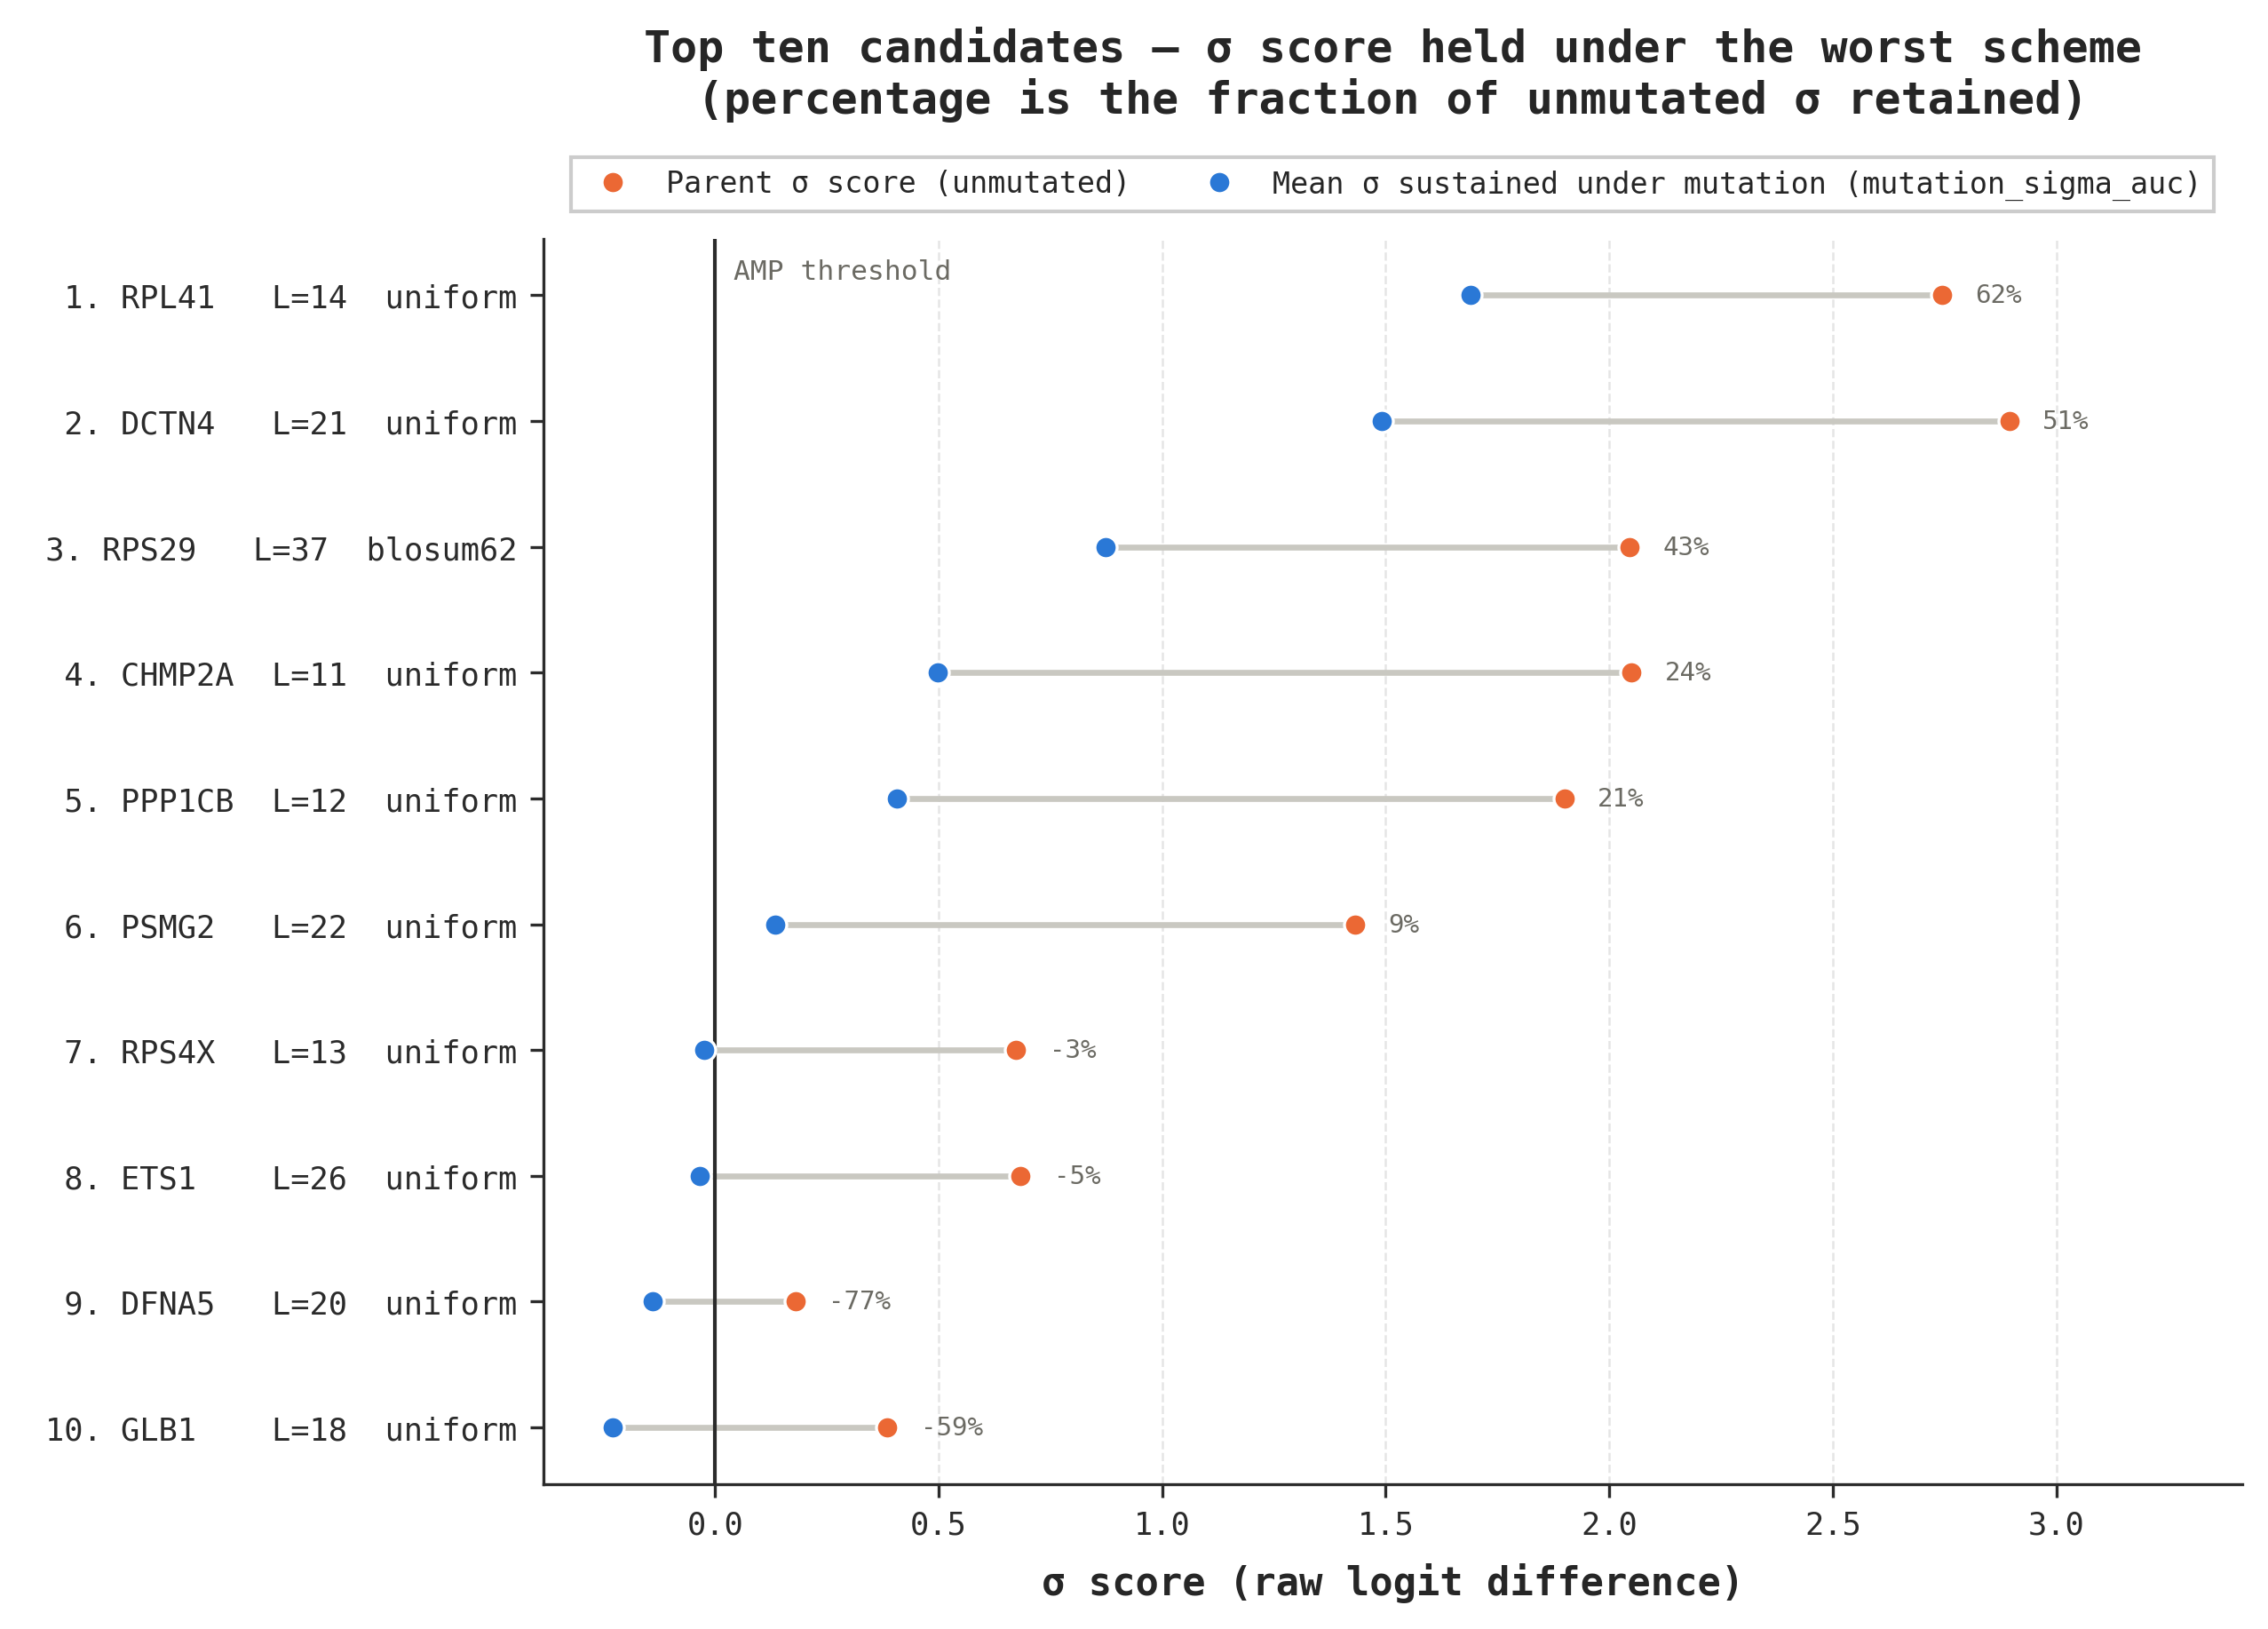

In [32]:
PARENT_COLOR = "#eb6834"
SUSTAINED_COLOR = "#2a78d6"

panel = worst.iloc[::-1]
positions = np.arange(len(panel))

figure, axis = plt.subplots(figsize=(8.4, 0.40 * len(panel) + 2.0), dpi=300, layout="constrained")
axis.hlines(positions, panel["mutation_sigma_auc"], panel["parent_sigma"],
            color="#c9c8c1", linewidth=1.6, zorder=1)
axis.plot(panel["parent_sigma"], positions, "o", markersize=6, color=PARENT_COLOR,
          markeredgecolor="white", markeredgewidth=0.8, zorder=3, linestyle="none",
          label="Parent σ score (unmutated)")
axis.plot(panel["mutation_sigma_auc"], positions, "o", markersize=6, color=SUSTAINED_COLOR,
          markeredgecolor="white", markeredgewidth=0.8, zorder=3, linestyle="none",
          label="Mean σ sustained under mutation (mutation_sigma_auc)")

for position, row in zip(positions, panel.itertuples()):
    axis.annotate(f"{row.mutation_sigma_retained:.0%}",
                  xy=(row.parent_sigma, position), textcoords="offset points",
                  xytext=(9, 0), fontsize=7, color="#6b6a63", va="center")

labels = [f"{rank:>2}. {pid:<7} L={length:>2}  {scheme}"
          for rank, pid, length, scheme in zip(panel["rank"], panel["parent_id"],
                                               panel["length"], panel["scheme"])]
axis.set_yticks(positions)
axis.set_yticklabels(labels)
axis.axvline(0.0, color=SPINE_COLOR, linewidth=1.0)
axis.annotate("AMP threshold", xy=(0.0, 1.0), xycoords=("data", "axes fraction"),
              textcoords="offset points", xytext=(5, -11), fontsize=7.5, color="#6b6a63")
axis.set_xlim(right=float(panel["parent_sigma"].max()) * 1.18)
axis.set_xlabel("σ score (raw logit difference)", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_title("Top ten candidates — σ score held under the worst scheme\n"
               "(percentage is the fraction of unmutated σ retained)",
               fontsize=TITLE_SIZE, fontweight="bold", pad=34)
axis.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2,
            fontsize=8, frameon=True, fancybox=False, framealpha=1)
style_axes(axis, grid_axis="x")
plt.show()

### Caveat — nominal `p` is not a distinct dose at these lengths

`k = floor(p·L + 0.5)`, so several nominal `p` levels collapse onto the same substitution count for
short peptides. Those cells re-measure a dose already measured, which shows up as a stair-step in
the curves above and makes `retention_auc` weight doses unevenly in a way that varies with length.

This bites harder here than on the full candidate set: these ten run from 11 to 37 aa, and the
shortest resolve the nine nominal levels into only six distinct substitution counts.

In [33]:
redundancy = curves.copy()
redundancy["duplicate_k"] = redundancy.duplicated(["parent_id", "scheme", "k_requested"])
by_peptide = redundancy.groupby("parent_id").agg(
    length=("length", "first"),
    cells=("duplicate_k", "size"),
    redundant=("duplicate_k", "sum"),
    distinct_k=("k_requested", "nunique"),
)
by_peptide["k_values"] = (redundancy.groupby("parent_id")["k_requested"]
                          .apply(lambda column: ", ".join(map(str, sorted(column.unique())))))
by_peptide["fraction"] = (by_peptide["redundant"] / by_peptide["cells"]).round(3)
by_peptide = by_peptide.loc[PEPTIDE_ORDER]

overall = redundancy["duplicate_k"].mean()
print(f"redundant cells: {redundancy['duplicate_k'].sum()} / {len(redundancy)} ({overall:.1%})")
print(f"variants spent re-measuring a known dose: "
      f"{redundancy.loc[redundancy['duplicate_k'], 'n_variants'].sum():,}")
display(by_peptide[["length", "distinct_k", "cells", "redundant", "fraction", "k_values"]])

redundant cells: 33 / 270 (12.2%)
variants spent re-measuring a known dose: 16,500


,length,distinct_k,cells,redundant,fraction,k_values
parent_id,,,,,,
RPL41,14,7,27,6,0.222,"1, 2, 3, 4, 5, 6, 7"
DCTN4,21,9,27,0,0.000,"2, 3, 4, 5, 6, 7, 8, 9, 11"
RPS29,37,9,27,0,0.000,"4, 6, 7, 9, 11, 13, 15, 17, 19"
CHMP2A,11,6,27,9,0.333,"1, 2, 3, 4, 5, 6"
PPP1CB,12,6,27,9,0.333,"1, 2, 3, 4, 5, 6"
PSMG2,22,9,27,0,0.000,"2, 3, 4, 6, 7, 8, 9, 10, 11"
RPS4X,13,7,27,6,0.222,"1, 2, 3, 4, 5, 6, 7"
ETS1,26,9,27,0,0.000,"3, 4, 5, 7, 8, 9, 10, 12, 13"
DFNA5,20,9,27,0,0.000,"2, 3, 4, 5, 6, 7, 8, 9, 10"


## Deletion — truncation from one end

Reads the pinned `length_analysis --mode deletion` run over the same ten
(`gnn-scaled-deletion-…`). Each peptide is truncated from one terminus at a time by
`k = round(p·L)` residues, at `p = 0.05, 0.1, 0.2`, giving 10 × 2 × 3 = 60 variants.

Unlike the mutation sweep, **every variant is folded on its own** — truncation changes the
chain, so there is no fixed-backbone shortcut. Both this run and the extension run below fold
into the shared `generated/length_cache`, which is why their unextended baselines agree.

Two things to know before reading the figures:

- **Truncation does cost calls here.** 8 of the 60 variants fall below the AMP threshold, all
  of them from the three peptides that start closest to it — DFNA5 (4 of its 6), ETS1 (3) and
  RPS4X (1). This is what the absolute-σ panels show and a Δσ panel cannot: a peptide whose σ
  drops by 0.3 matters very differently depending on whether it began at 0.02 or at 2.7.
- **`p` is the requested dose, `k` is what lands.** `k = floor(p·L + 0.5)` differs per peptide,
  and at these lengths several `p` levels collapse onto one `k` (CHMP2A and PPP1CB resolve all
  three into `k ∈ {1, 2}`). The figures plot `p`, where the ten share an axis; the table lists
  each peptide's `k`.

In [34]:
DELETION_CURVES_CSV = run_csv(DATA_ROOT, "length_deletion_curves.csv")
DELETION_ROBUSTNESS_CSV = run_csv(DATA_ROOT, "length_deletion_robustness.csv")

TERMINUS_ORDER = ["N", "C"]
TERMINUS_COLOR = {"N": "#2a78d6", "C": "#eb6834"}
TERMINUS_MARKER = {"N": "o", "C": "s"}

# margin_auc means the deletion sweep here, not the mutation one.
DELETION_RENAMES = SIGMA_RENAMES | {
    "delta_logit_margin": "delta_sigma",
    "margin_auc": "deletion_sigma_auc",
}
deletion_curves = pd.read_csv(DELETION_CURVES_CSV).rename(columns=DELETION_RENAMES)
deletion_robustness = pd.read_csv(DELETION_ROBUSTNESS_CSV).rename(columns=DELETION_RENAMES)

deletion_manifest = json.loads((DELETION_CURVES_CSV.parent / "run_manifest.json").read_text())
deletion_parent_rows = deletion_robustness.drop_duplicates("parent_id").set_index("parent_id")
deletion_parents = deletion_parent_rows["parent_sigma"]
# Absolute panels start each curve at the untruncated score, so the parent
# columns are carried onto the per-variant rows.
for column in ("parent_sigma", "parent_prob_AMP"):
    deletion_curves[column] = deletion_curves["parent_id"].map(deletion_parent_rows[column])

DELETION_P_LEVELS = sorted(deletion_curves["p"].unique())
DELETION_P_LEVELS_FROM_ORIGINAL = [0.0, *DELETION_P_LEVELS]
lost = deletion_curves[deletion_curves["pred"] == 0]

print("Run:   ", deletion_manifest["run_id"],
      f"({deletion_manifest['config']['effective']['deletion']})")
print("Curves:", DELETION_CURVES_CSV.name, f"({len(deletion_curves)} rows)")
print(f"p levels {DELETION_P_LEVELS}, termini {sorted(deletion_curves['terminus'].unique())}")
print(f"variants losing the AMP call: {len(lost)} / {len(deletion_curves)}")
# The length runs fold their own copies into generated/length_cache, so a parent's
# baseline here need not equal the mutation section's byte-for-byte.
drift = (deletion_parents - parents.set_index("parent_id")["parent_sigma"]).abs()
print(f"parent σ vs the mutation section: {int((drift < 1e-6).sum())}/{len(drift)} identical, "
      f"largest gap {drift.max():.3f} ({drift.idxmax()})")

Run:    2026-11-18_11-17 ({'p_levels': [0.05, 0.1, 0.2], 'termini': ['N', 'C']})
Curves: length_deletion_curves.csv (60 rows)
p levels [np.float64(0.05), np.float64(0.1), np.float64(0.2)], termini ['C', 'N']
variants losing the AMP call: 8 / 60
parent σ vs the mutation section: 3/10 identical, largest gap 0.160 (DFNA5)


### σ and P(AMP) versus deletion level

The x axis is **`p`, the requested fraction**, so all ten peptides share the same three
positions and the mean across them is defined at each one. Each line starts at **p = 0**, the
untruncated peptide, so the absolute score is read against where that peptide began and against
the AMP threshold drawn on the same axis.

The residues actually removed are `k = floor(p·L + 0.5)`, which is not the same ladder for every
peptide:

- **RPS29** (L = 37) starts at `k = 2`, because `0.05 × 37 = 1.85` rounds up. Every other peptide
  starts at `k = 1`.
- At the top dose the ladders are nothing alike: `k = 2` for CHMP2A (L = 11) against `k = 7` for
  RPS29.
- At the short end successive `p` levels collapse onto one `k`: CHMP2A and PPP1CB both give
  `k = 1` at `p = 0.05` and again at `p = 0.1`, so those two points are the same variant scored
  twice and the line is flat there by construction.

The table below lists each peptide's `k` at all three levels, so nothing is lost by plotting `p`.

The **N panel's x axis runs right to left**, so the pair reads the way the peptide does — the N end on the left, the C end on the right, each one worked on from the outside in.

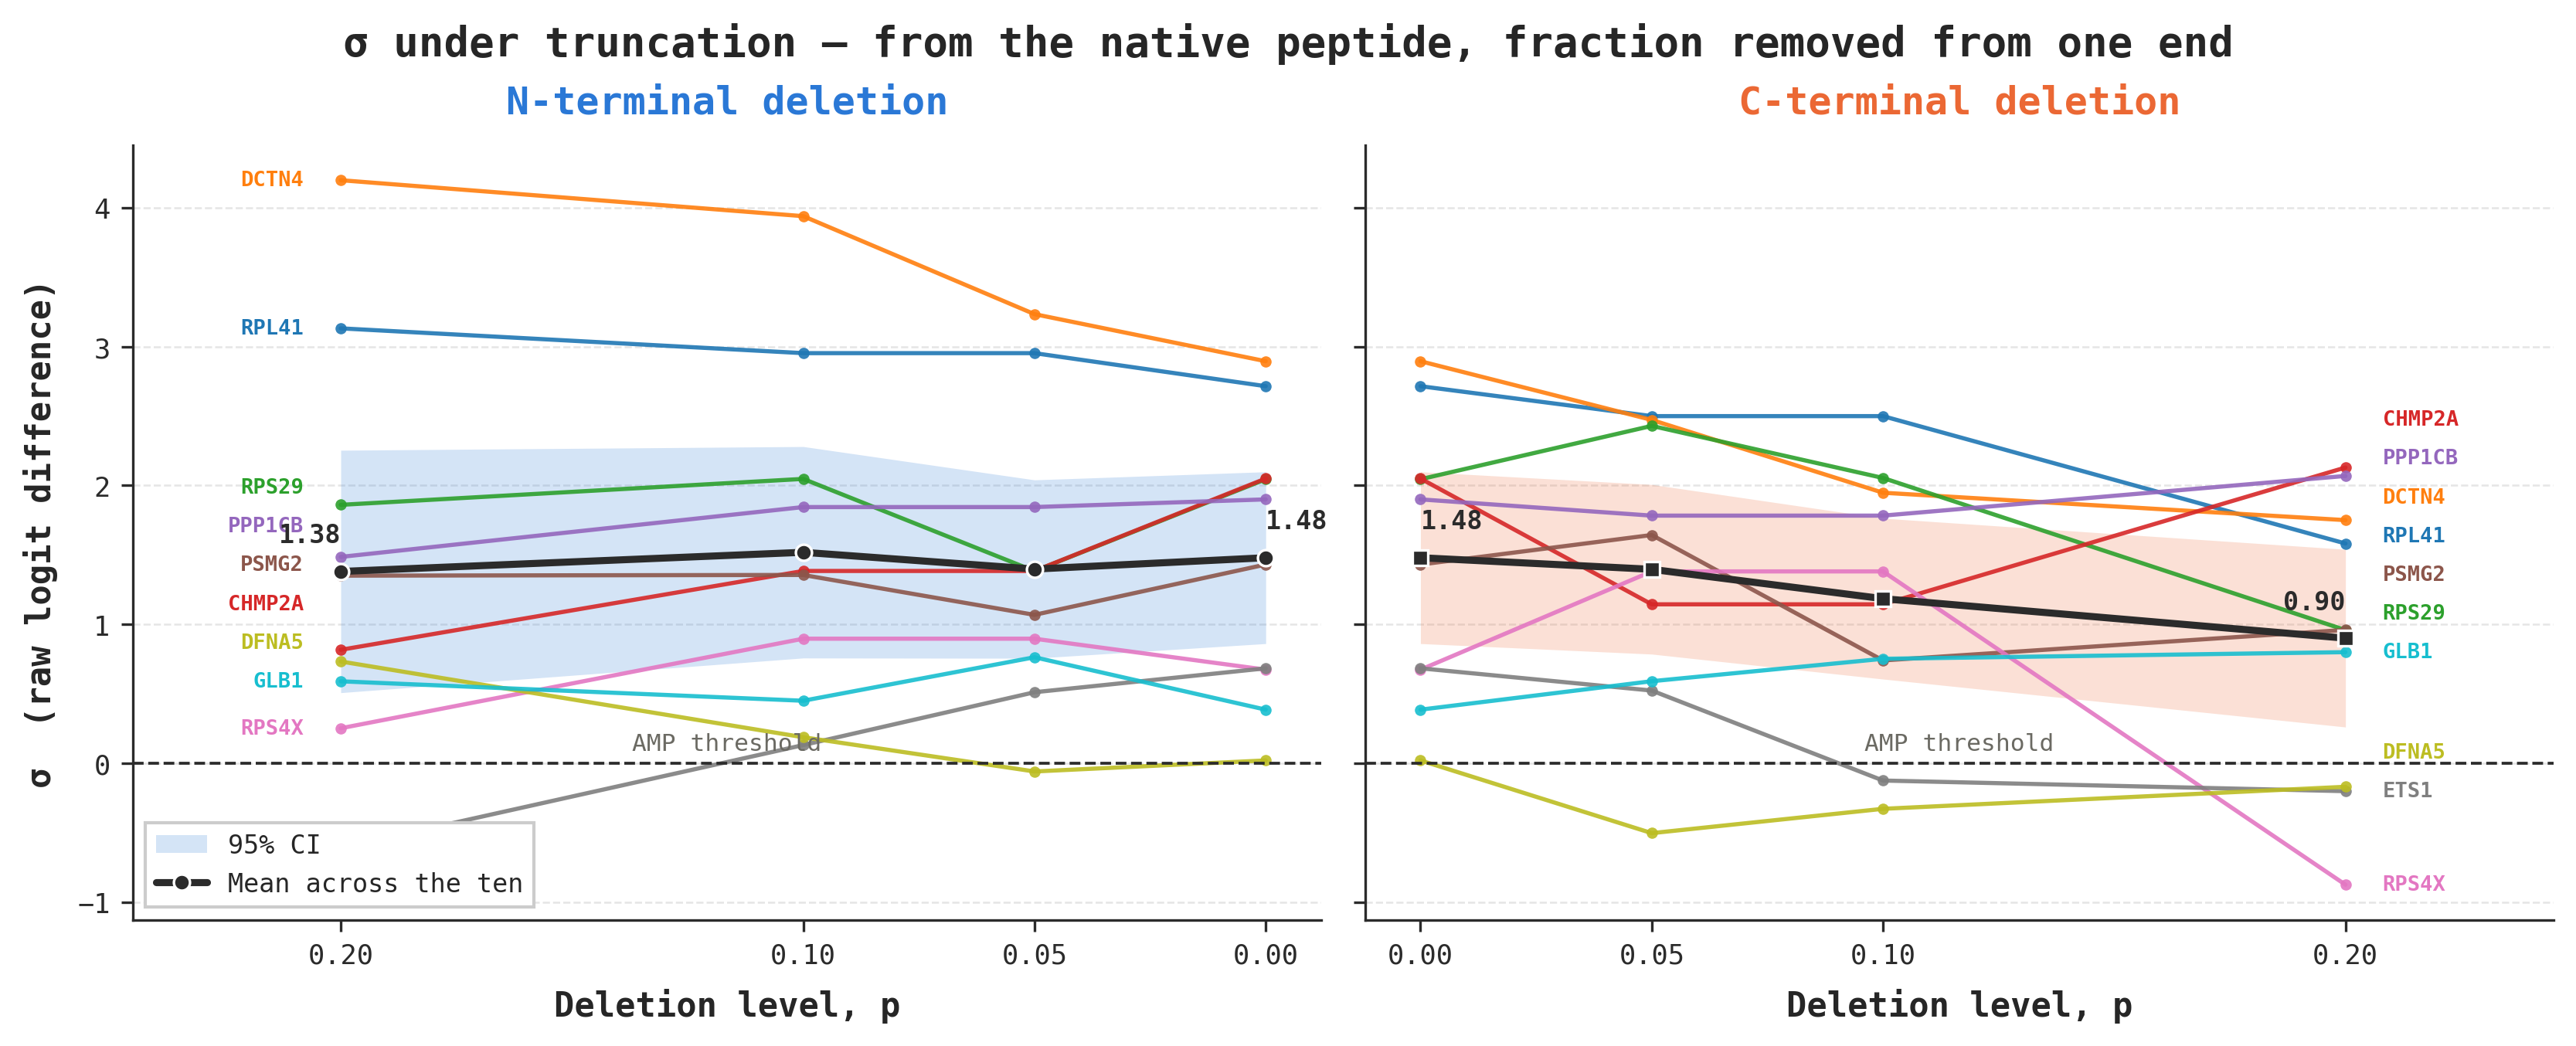

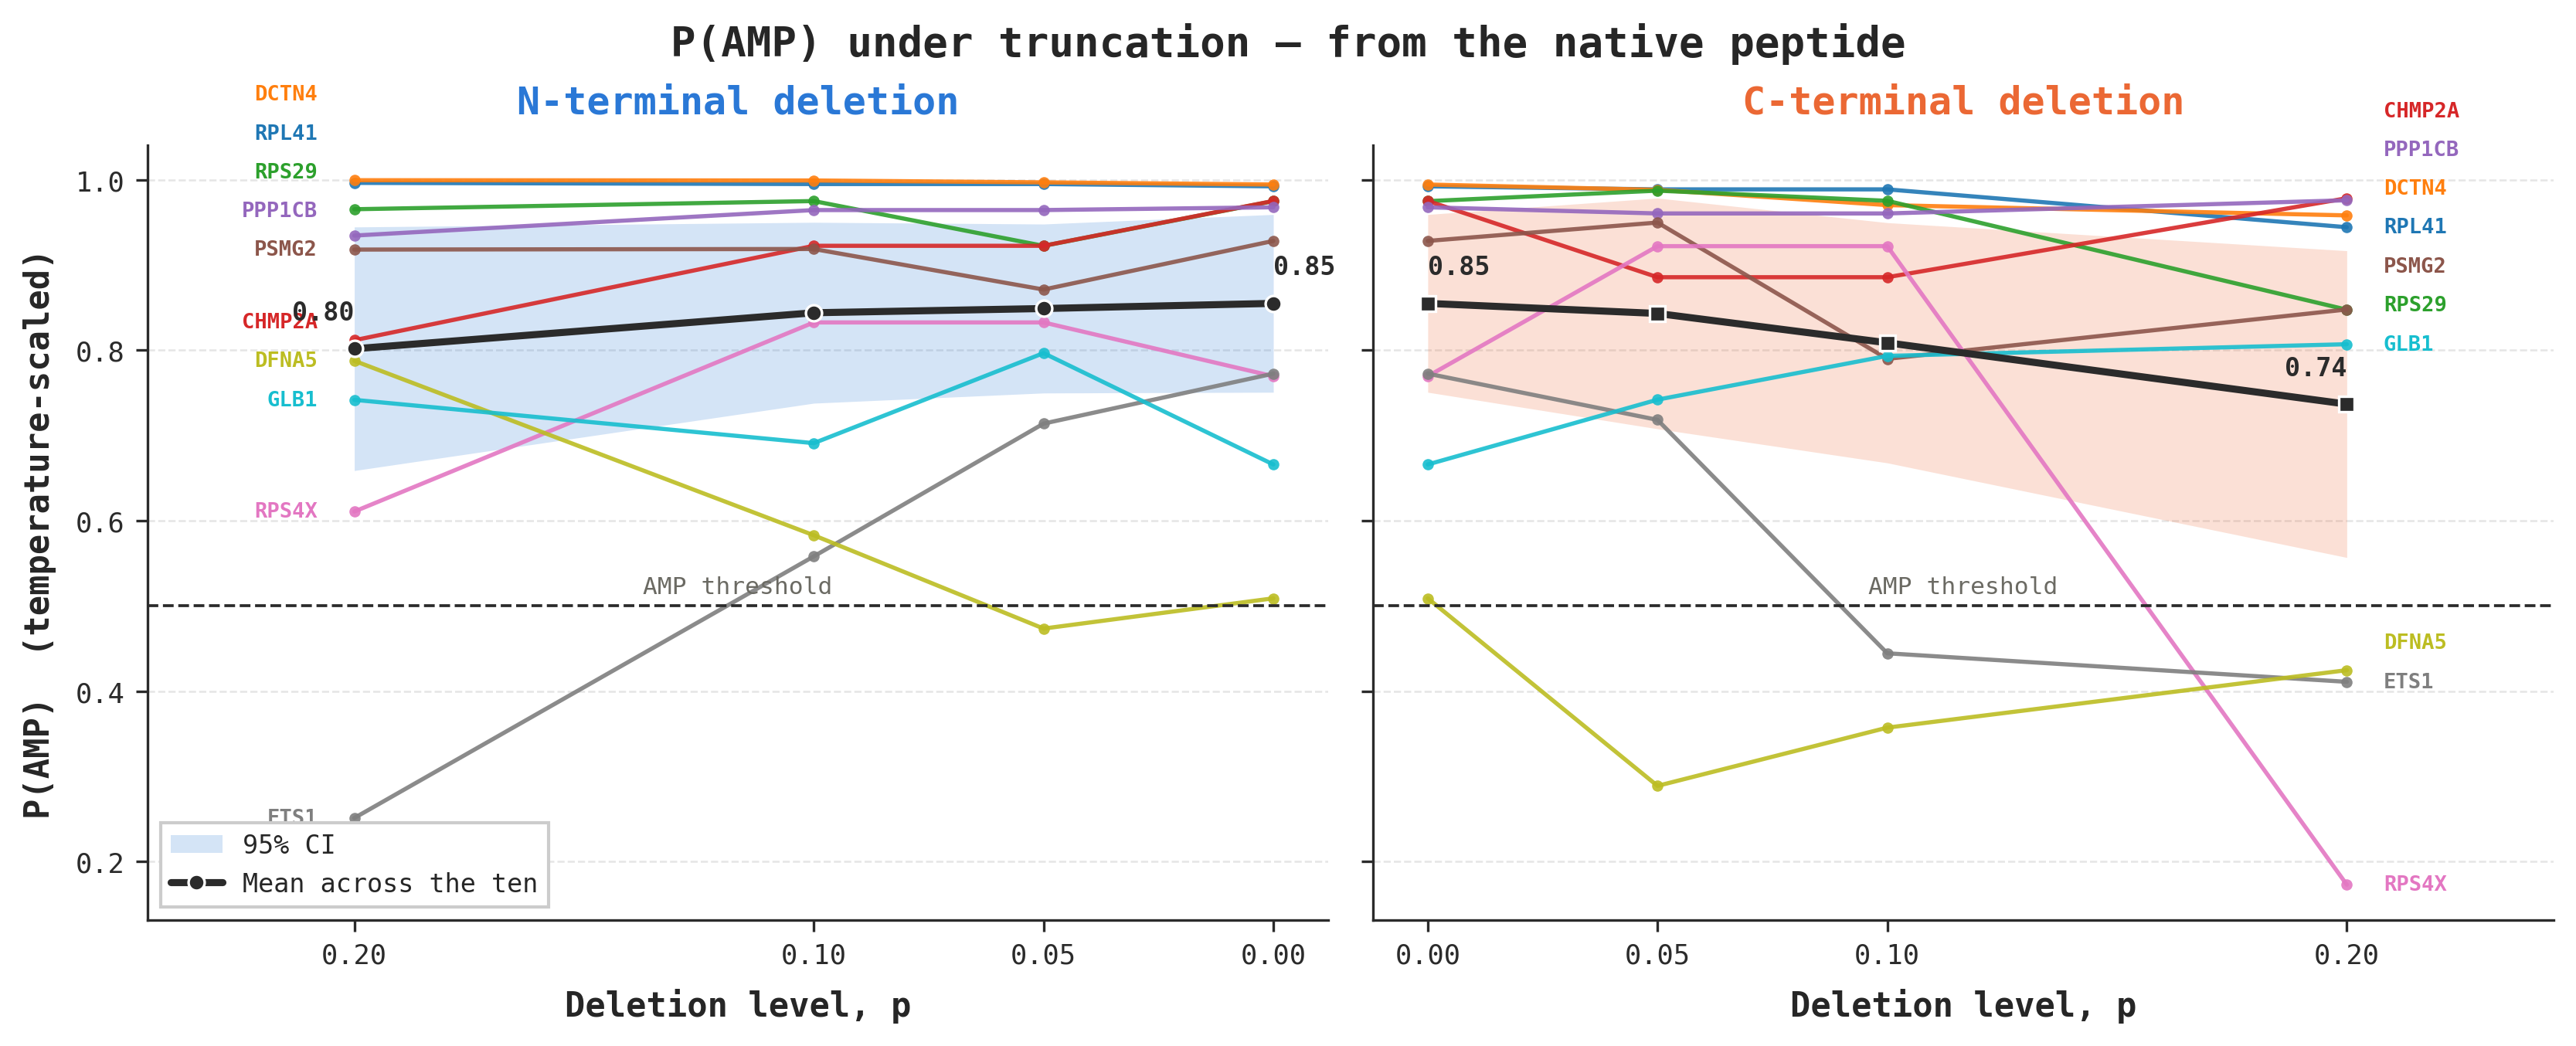

In [35]:
def plot_deletion_vs_p(value: str, parent_value: str, threshold: float,
                       y_label: str, title: str) -> None:
    """Absolute score against p, the requested fraction, so all ten share three positions.

    k = floor(p*L + 0.5) differs per peptide - the table below lists each one's - so an
    axis in residues gives every peptide its own start and end point. Each line starts at
    p = 0, the untruncated peptide's own score.
    """
    anchored = with_original(deletion_curves, {value: parent_value},
                             ["parent_id", "terminus"])
    figure, axes = plt.subplots(1, len(TERMINUS_ORDER), figsize=(11.0, 4.4), dpi=300,
                                sharey=True, layout="constrained")
    low, high = anchored[value].min(), anchored[value].max()
    gap = (high - low) * 0.055

    for axis, terminus in zip(axes, TERMINUS_ORDER):
        subset = anchored[anchored["terminus"] == terminus]
        lines = subset.pivot(index="p", columns="parent_id", values=value)[PEPTIDE_ORDER]
        for peptide in PEPTIDE_ORDER:
            axis.plot(lines.index, lines[peptide], color=PEPTIDE_COLOR[peptide], linewidth=1.3,
                      marker="o", markersize=3.5, markeredgewidth=0, alpha=0.9)

        ends = lines.iloc[-1].sort_values()
        for peptide, height in zip(ends.index, ladder_heights(ends.to_numpy(), gap)):
            axis.annotate(peptide, xy=(DELETION_P_LEVELS[-1], ends[peptide]),
                          xytext=(DELETION_P_LEVELS[-1] + 0.008, height), fontsize=6.5,
                          fontweight="bold", color=PEPTIDE_COLOR[peptide], va="center",
                          ha="right" if terminus == "N" else "left", annotation_clip=False)

        stats = mean_ci(subset, value)
        axis.fill_between(stats["p"], stats["low"], stats["high"], color=TERMINUS_COLOR[terminus],
                          alpha=0.2, linewidth=0, label="95% CI")
        axis.plot(stats["p"], stats["mean"], color=SPINE_COLOR, linewidth=2.2,
                  marker=TERMINUS_MARKER[terminus], markersize=5, markeredgecolor="white",
                  markeredgewidth=0.8, zorder=5, label="Mean across the ten")
        for index, align in ((0, "left"), (-1, "right")):
            axis.annotate(f"{stats['mean'].iloc[index]:.2f}",
                          (stats["p"].iloc[index], stats["mean"].iloc[index]),
                          textcoords="offset points", xytext=(0, 9), ha=align,
                          fontsize=8, fontweight="bold", color=SPINE_COLOR, zorder=6)

        axis.axhline(threshold, color=SPINE_COLOR, linewidth=0.9, linestyle="--")
        axis.annotate("AMP threshold", xy=(0.5, threshold), xycoords=("axes fraction", "data"),
                      textcoords="offset points", xytext=(0, 4), ha="center",
                      fontsize=7.5, color="#6b6a63")
        axis.set_title(f"{terminus}-terminal deletion", fontsize=TITLE_SIZE, fontweight="bold",
                       pad=10, color=TERMINUS_COLOR[terminus])
        axis.set_xlabel("Deletion level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
        axis.set_xticks(DELETION_P_LEVELS_FROM_ORIGINAL)
        # The N panel runs right to left, so the two panels together read as the
        # peptide does: the N end on the left, the C end on the right, each eaten
        # away from the outside in.
        span = (-0.012, DELETION_P_LEVELS[-1] + 0.045)
        axis.set_xlim(*(span[::-1] if terminus == "N" else span))
        style_axes(axis)

    axes[0].set_ylabel(y_label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    axes[0].legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
    figure.suptitle(title, fontsize=TITLE_SIZE + 1, fontweight="bold")
    plt.show()


plot_deletion_vs_p(
    "sigma", "parent_sigma", SIGMA_THRESHOLD,
    "σ  (raw logit difference)",
    "σ under truncation — from the native peptide, fraction removed from one end",
)
plot_deletion_vs_p(
    "prob_AMP", "parent_prob_AMP", 0.5,
    "P(AMP)  (temperature-scaled)",
    "P(AMP) under truncation — from the native peptide",
)

### Per-terminus summary

`sigma_auc` is the mean σ held across the three doses and `sigma_slope` is dσ/dp, so a positive
slope means truncation *raised* the score. Rows keep the sustained-σ ranking from the mutation
section.

In [36]:
deletion_summary = (
    deletion_robustness.pivot(index="parent_id", columns="terminus",
                              values=["deletion_sigma_auc", "mean_delta_prob_AMP", "sigma_slope"])
    .loc[PEPTIDE_ORDER]
)
deletion_summary.columns = [f"{terminus}_{name.replace('deletion_sigma_auc', 'sigma_auc')}"
                            for name, terminus in deletion_summary.columns]
k_by_peptide = (deletion_curves[deletion_curves["terminus"] == "N"]
                .sort_values("p").groupby("parent_id")["k"]
                .apply(lambda column: ", ".join(map(str, column))))
deletion_summary.insert(0, "parent_sigma", deletion_parents.loc[PEPTIDE_ORDER])
deletion_summary.insert(0, "k at p=0.05/0.1/0.2", k_by_peptide.loc[PEPTIDE_ORDER])
deletion_summary.insert(0, "length", deletion_robustness.drop_duplicates("parent_id")
                        .set_index("parent_id")["length"].loc[PEPTIDE_ORDER])

numeric = [column for column in deletion_summary.columns if column not in
           {"length", "k at p=0.05/0.1/0.2"}]
display(deletion_summary.style.format("{:.3f}", subset=numeric)
        .format("{:.0f}", subset=["length"]))

,length,k at p=0.05/0.1/0.2,parent_sigma,C_sigma_auc,N_sigma_auc,C_mean_delta_prob_AMP,N_mean_delta_prob_AMP,C_sigma_slope,N_sigma_slope
parent_id,,,,,,,,,
RPL41,14,"1, 1, 3",2.715,2.194,3.012,-0.018,0.003,-6.552,1.276
DCTN4,21,"1, 2, 4",2.895,1.969,3.908,-0.022,0.004,-4.405,5.881
RPS29,37,"2, 4, 7",2.045,1.751,1.874,-0.038,-0.021,-9.968,2.458
CHMP2A,11,"1, 1, 2",2.050,1.472,1.195,-0.059,-0.090,7.037,-4.055
PPP1CB,12,"1, 1, 2",1.900,1.878,1.725,-0.002,-0.013,2.042,-2.563
PSMG2,22,"1, 2, 4",1.431,0.964,1.306,-0.066,-0.026,-3.591,1.606
RPS4X,13,"1, 1, 3",0.674,0.629,0.682,-0.097,-0.011,-16.117,-4.607
ETS1,26,"1, 3, 5",0.683,-0.042,-0.053,-0.248,-0.265,-4.249,-7.469
DFNA5,20,"1, 2, 4",0.020,-0.305,0.328,-0.152,0.106,2.134,5.305


## Insertion — extension into the native flanks

Reads the pinned `length_analysis` extension run (`gnn-scaled-insertion-…`). Each peptide is
grown back into the residues that flank it in its source protein, up to
`max_flank_fraction = 0.5` of its own length on each side, at `stride = 1`, taking the full
left × right **product** — 862 variants from 11 to 56 aa, each one folded separately.

The flank, not the fraction, is the binding limit for two of them: **RPL41** starts at its
protein's N-terminus, so it has no left flank at all and only grows on the C side, and **RPS29**
has a single residue to its left against an 18-residue allowance.

Extension is the one direction that can *improve* a candidate, and 9 of the 10 do — DFNA5 is
the exception, where no extension beats leaving it alone. It is also not free: 218 of the 862
variants fall below the AMP threshold, concentrated in the peptides that start near it
(DFNA5 120, GLB1 57, RPS4X 21).

In [37]:
INSERTION_CSV = run_csv(DATA_ROOT, "length_predictions.csv")

insertion = pd.read_csv(INSERTION_CSV).rename(columns=SIGMA_RENAMES)
insertion_manifest = json.loads((INSERTION_CSV.parent / "run_manifest.json").read_text())

# The parent is the unextended variant of the same run, so Δ never crosses runs.
insertion_parents = (insertion[(insertion["left_added"] == 0) & (insertion["right_added"] == 0)]
                     .set_index("parent_id"))
insertion["parent_sigma"] = insertion["parent_id"].map(insertion_parents["sigma"])
insertion["delta_sigma"] = insertion["sigma"] - insertion["parent_sigma"]
insertion["delta_prob_AMP"] = (insertion["prob_AMP"]
                               - insertion["parent_id"].map(insertion_parents["prob_AMP"]))
insertion["added"] = insertion["left_added"] + insertion["right_added"]

flanks = insertion.groupby("parent_id").agg(variants=("variant_id", "size"),
                                            left_max=("left_added", "max"),
                                            right_max=("right_added", "max"))
best = insertion.loc[insertion.groupby("parent_id")["sigma"].idxmax()].set_index("parent_id")

print("Run:   ", insertion_manifest["run_id"],
      f"({insertion_manifest['config']['effective']['length']})")
print(f"variants: {len(insertion)} over {insertion['parent_id'].nunique()} peptides, "
      f"lengths {insertion['variant_length'].min()}-{insertion['variant_length'].max()} aa")
dropped = insertion[insertion["pred"] == 0].groupby("parent_id").size()
print(f"losing the AMP call: {int(dropped.sum())} "
      + ("(" + ", ".join(f"{peptide} x{count}" for peptide, count in dropped.items()) + ")"
         if len(dropped) else ""))
print(f"improved on the parent: {int((best['delta_sigma'] > 1e-9).sum())}/{len(best)} peptides")
# The combined axis below only holds while both length runs fold from one cache.
shared = (insertion_parents["sigma"] - deletion_parents).abs().max()
print(f"parent σ vs the deletion run: largest gap {shared:.2e} "
      + ("(same structures)" if shared < 1e-4 else "— DIFFERENT STRUCTURES, the combined axis "
         "below mixes two baselines"))
# A flank shorter than the allowance caps the sweep before 50% does.
capped = flanks[(flanks["left_max"] == 0) | (flanks["right_max"] == 0)]
for peptide, row in capped.iterrows():
    print(f"  {peptide}: flank-limited, left_max={row['left_max']} right_max={row['right_max']}")

Run:    2026-11-18_11-17_02 ({'fold_batch_size': 16, 'max_flank_fraction': 0.5, 'separate_termini': False, 'stride': 1, 'termini': ['N', 'C']})
variants: 862 over 10 peptides, lengths 11-56 aa
losing the AMP call: 218 (CHMP2A x1, DFNA5 x120, ETS1 x11, GLB1 x57, PPP1CB x4, PSMG2 x4, RPS4X x21)
improved on the parent: 9/10 peptides
parent σ vs the deletion run: largest gap 2.38e-07 (same structures)
  RPL41: flank-limited, left_max=0 right_max=7


### The (N, C) landscape

One panel per peptide, the variant's **absolute σ** over every left/right pair the sweep covers,
on one shared scale centred on the AMP threshold: red is above the threshold, blue below, and
white is the decision boundary itself. The square is the unextended peptide at (0, 0), the open
circle the best variant found, and × marks a cell the model no longer calls AMP.

Plotting σ rather than Δσ keeps the panels comparable with each other — a peptide sitting far
above the line looks different from one hovering on it, which a per-peptide Δ scale hides. Each
panel's title still carries the parent → best σ, so the gain is readable alongside.

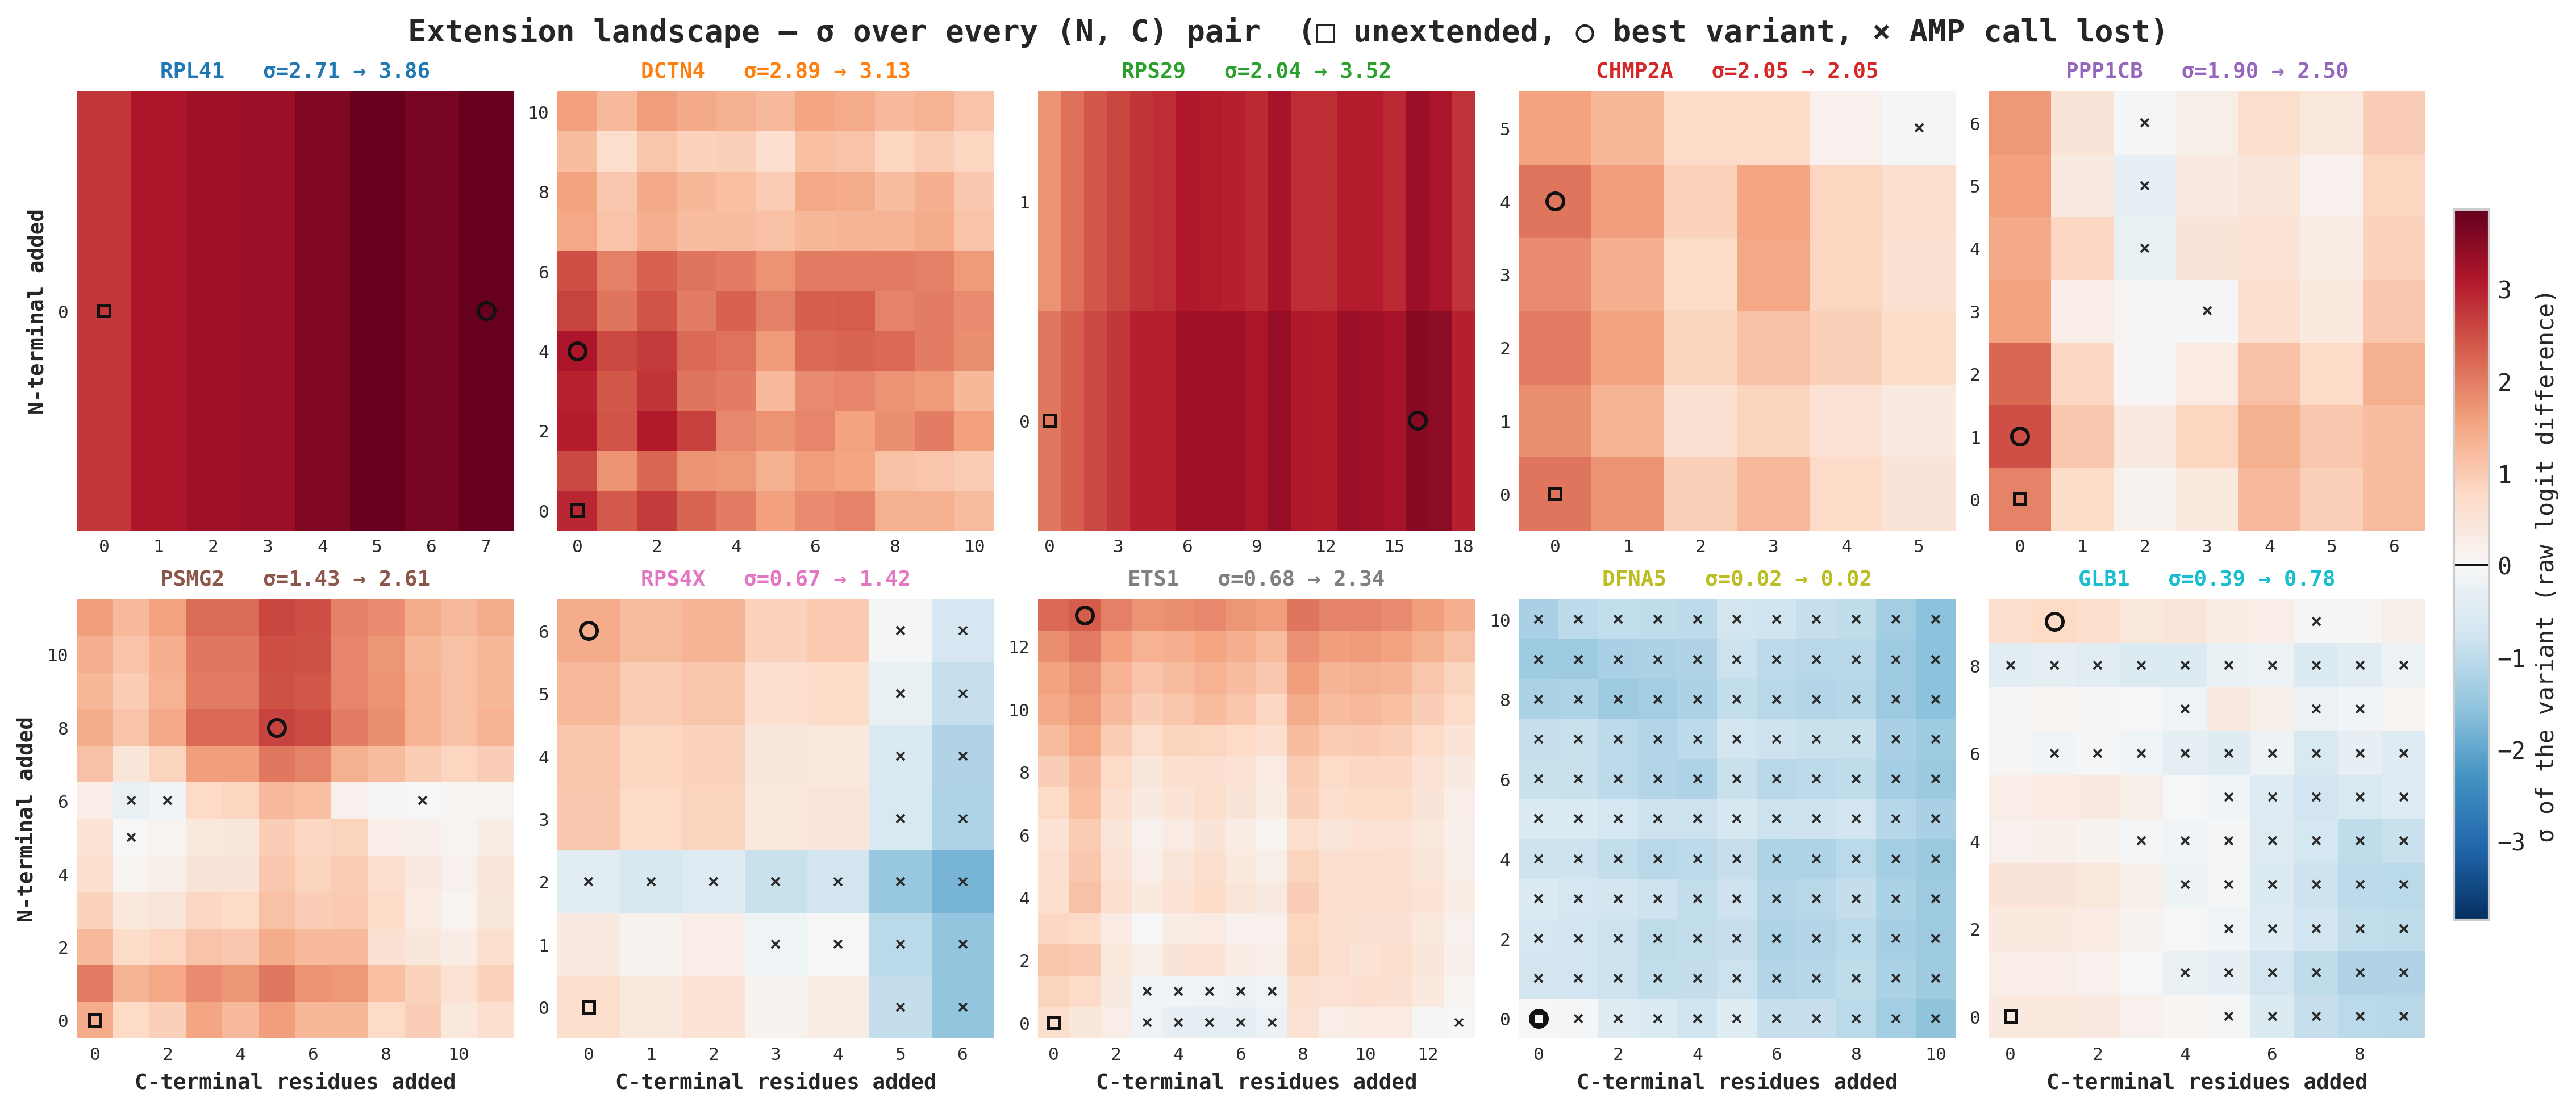

In [38]:
# Shared, symmetric about the AMP threshold, so white is the decision boundary and a
# panel's colour says whether that variant is called an AMP - not merely whether it
# improved on its parent.
SIGMA_SPAN = float(np.abs(insertion["sigma"] - SIGMA_THRESHOLD).max())

figure, axes = plt.subplots(2, 5, figsize=(15.0, 6.4), dpi=300, layout="constrained")
for axis, peptide in zip(axes.flat, PEPTIDE_ORDER):
    subset = insertion[insertion["parent_id"] == peptide]
    grid = subset.pivot(index="left_added", columns="right_added", values="sigma")
    image = axis.imshow(grid.to_numpy(), cmap="RdBu_r",
                        vmin=SIGMA_THRESHOLD - SIGMA_SPAN, vmax=SIGMA_THRESHOLD + SIGMA_SPAN,
                        origin="lower", aspect="auto")

    # An x marks a cell the model no longer calls AMP; the parent sits at (0, 0).
    dropped = subset[subset["pred"] == 0]
    if len(dropped):
        axis.plot(dropped["right_added"], dropped["left_added"], "x", color="#2b2b2b",
                  markersize=3.5, markeredgewidth=0.9, linestyle="none")
    peak = best.loc[peptide]
    axis.plot(peak["right_added"], peak["left_added"], "o", markersize=7,
              markerfacecolor="none", markeredgecolor="#111111", markeredgewidth=1.4)
    # The unextended peptide, so the panel carries the score every cell is a change from.
    axis.plot(0, 0, "s", markersize=5, markerfacecolor="none", markeredgecolor="#111111",
              markeredgewidth=1.2)

    axis.set_title(f"{peptide}   σ={subset['parent_sigma'].iloc[0]:.2f} → {peak['sigma']:.2f}",
                   fontsize=9, fontweight="bold", pad=6, color=PEPTIDE_COLOR[peptide])
    axis.set_xticks(range(0, grid.shape[1], max(1, grid.shape[1] // 5)))
    axis.set_yticks(range(0, grid.shape[0], max(1, grid.shape[0] // 5)))
    axis.tick_params(labelsize=7.5, length=0, colors=SPINE_COLOR)
    axis.grid(False)
    for spine in axis.spines.values():
        spine.set_visible(False)

for axis in axes[1]:
    axis.set_xlabel("C-terminal residues added", fontsize=9, fontweight="bold", labelpad=4)
for axis in axes[:, 0]:
    axis.set_ylabel("N-terminal added", fontsize=9, fontweight="bold", labelpad=4)

bar = figure.colorbar(image, ax=axes, shrink=0.75, pad=0.012,
                      label="σ of the variant (raw logit difference)")
bar.ax.axhline(SIGMA_THRESHOLD, color="#111111", linewidth=1.2)
figure.suptitle("Extension landscape — σ over every (N, C) pair  "
                "(□ unextended, ○ best variant, × AMP call lost)",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### Single-terminus extension

The two edges of each landscape: the bottom row (C-terminal only) and the left column
(N-terminal only). The x axis is the **fraction of the peptide's own length added**, capped at
`max_flank_fraction = 0.5`, so an 11-mer growing by 5 and a 37-mer growing by 18 sit at the same
place. This is the comparable view to the deletion figure above, and the one to read if you want
to extend a candidate at one end only.

The **N panel's x axis runs right to left**, so the pair reads the way the peptide does — the N end on the left, the C end on the right, each one worked on from the outside in.

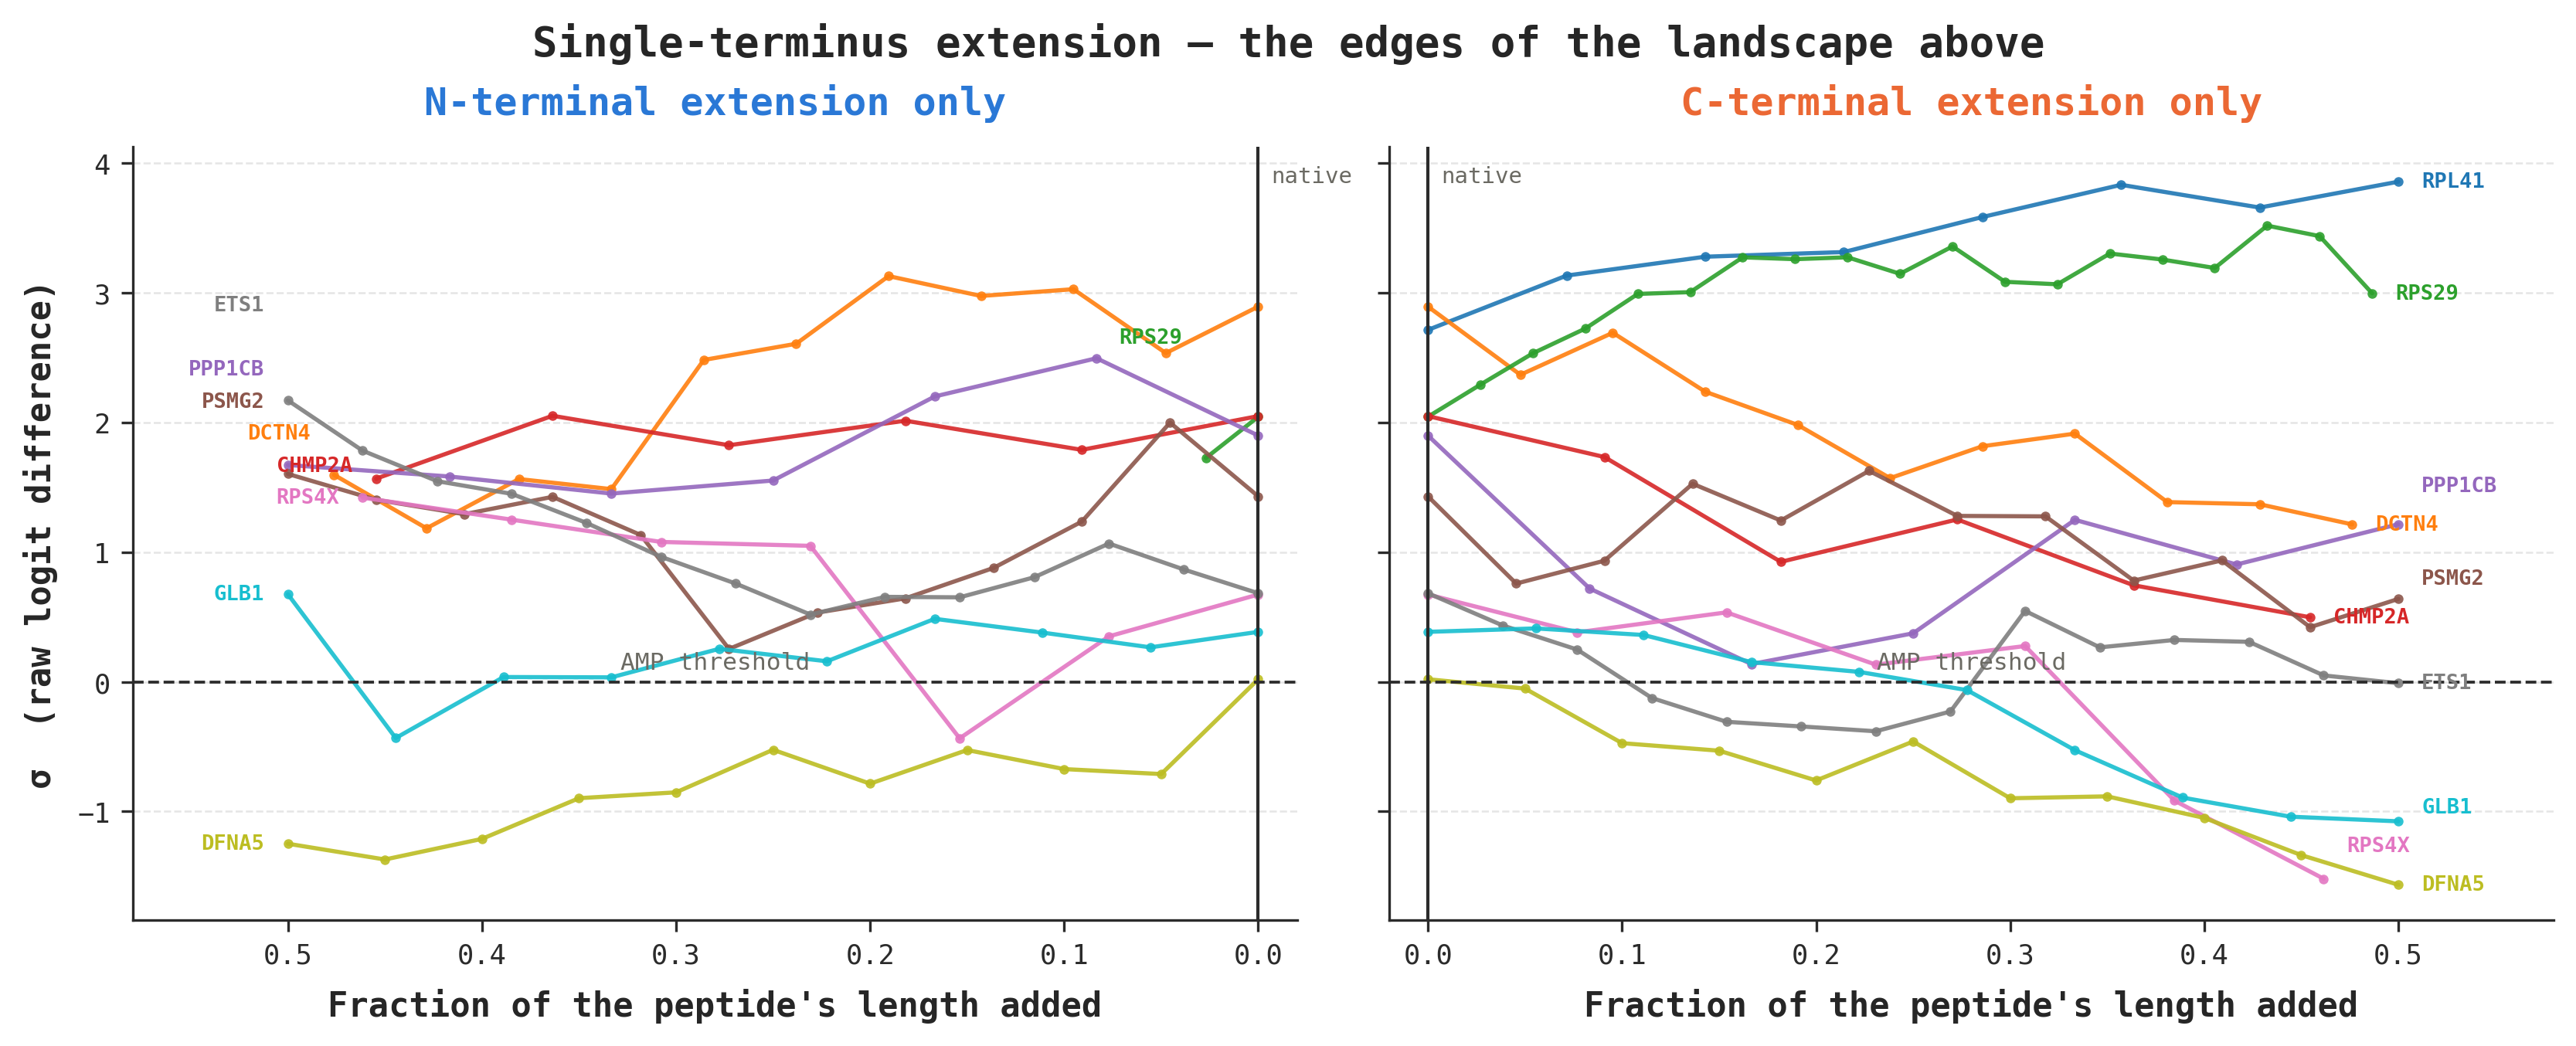

In [39]:
MARGINALS = [("N", insertion["right_added"] == 0, "left_added"),
             ("C", insertion["left_added"] == 0, "right_added")]

figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.4), dpi=300, sharey=True, layout="constrained")
for axis, (terminus, mask, column) in zip(axes, MARGINALS):
    # Fraction of the peptide's own length, so a 37-mer growing by 18 and an 11-mer
    # growing by 5 sit on the same axis. max_flank_fraction caps it at 0.5. Fraction 0
    # is the unextended peptide, so each line starts at its own native score.
    subset = insertion[mask].assign(fraction=lambda f: f[column] / f["core_length"])
    gap = (subset["sigma"].max() - subset["sigma"].min()) * 0.055
    ends = {}
    for peptide in PEPTIDE_ORDER:
        line = subset[subset["parent_id"] == peptide].sort_values("fraction")
        if len(line) < 2:
            continue
        axis.plot(line["fraction"], line["sigma"], color=PEPTIDE_COLOR[peptide],
                  linewidth=1.3, marker="o", markersize=3, markeredgewidth=0, alpha=0.9)
        ends[peptide] = (line["fraction"].iloc[-1], line["sigma"].iloc[-1])

    # Lines end at different x, so the ladder runs over every label in the panel:
    # separating them vertically is what stops two labels landing on each other.
    ordered = sorted(ends, key=lambda peptide: ends[peptide][1])
    for peptide, height in zip(ordered, ladder_heights([ends[p][1] for p in ordered], gap)):
        position, value = ends[peptide]
        axis.annotate(peptide, xy=(position, value), xytext=(position + 0.012, height),
                      fontsize=6.5, fontweight="bold", color=PEPTIDE_COLOR[peptide],
                      va="center", ha="right" if terminus == "N" else "left",
                      annotation_clip=False)

    axis.axhline(SIGMA_THRESHOLD, color=SPINE_COLOR, linewidth=0.9, linestyle="--")
    axis.annotate("AMP threshold", xy=(0.5, SIGMA_THRESHOLD), xycoords=("axes fraction", "data"),
                  textcoords="offset points", xytext=(0, 4), ha="center",
                  fontsize=7.5, color="#6b6a63")
    axis.axvline(0.0, color=SPINE_COLOR, linewidth=1.0)
    axis.annotate("native", xy=(0.0, 1.0), xycoords=("data", "axes fraction"),
                  textcoords="offset points", xytext=(4, -11), fontsize=7, color="#6b6a63")
    axis.set_title(f"{terminus}-terminal extension only", fontsize=TITLE_SIZE,
                   fontweight="bold", pad=10, color=TERMINUS_COLOR[terminus])
    axis.set_xlabel("Fraction of the peptide's length added", fontsize=LABEL_SIZE,
                    fontweight="bold", labelpad=6)
    # N grows leftwards out of the peptide, so its axis is mirrored.
    span = (-0.02, 0.58)
    axis.set_xlim(*(span[::-1] if terminus == "N" else span))
    axis.set_xticks([0.0, 0.1, 0.2, 0.3, 0.4, 0.5])
    style_axes(axis)

axes[0].set_ylabel("σ  (raw logit difference)", fontsize=LABEL_SIZE,
                   fontweight="bold", labelpad=6)
figure.suptitle("Single-terminus extension — the edges of the landscape above",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### Best variant reachable

The best σ found anywhere in each peptide's grid, against its unextended score. The annotation is
the extension that achieves it and the resulting length. RPL41 is the clearest case: seven
C-terminal residues take it from σ 2.71 to 3.86, the best any extension in the set reaches.
RPS29 gains the most ground (+1.47, σ 2.04 → 3.52 on sixteen C-terminal residues), and DFNA5 is
the one peptide where the parent is already its own best.

Note that this is the maximum over a sweep, not a held-out estimate — with 862 variants scored by
the same model that ranks them, some of the gain is the model's own noise. Treat the argmax as a
candidate to test, not as a measured improvement.

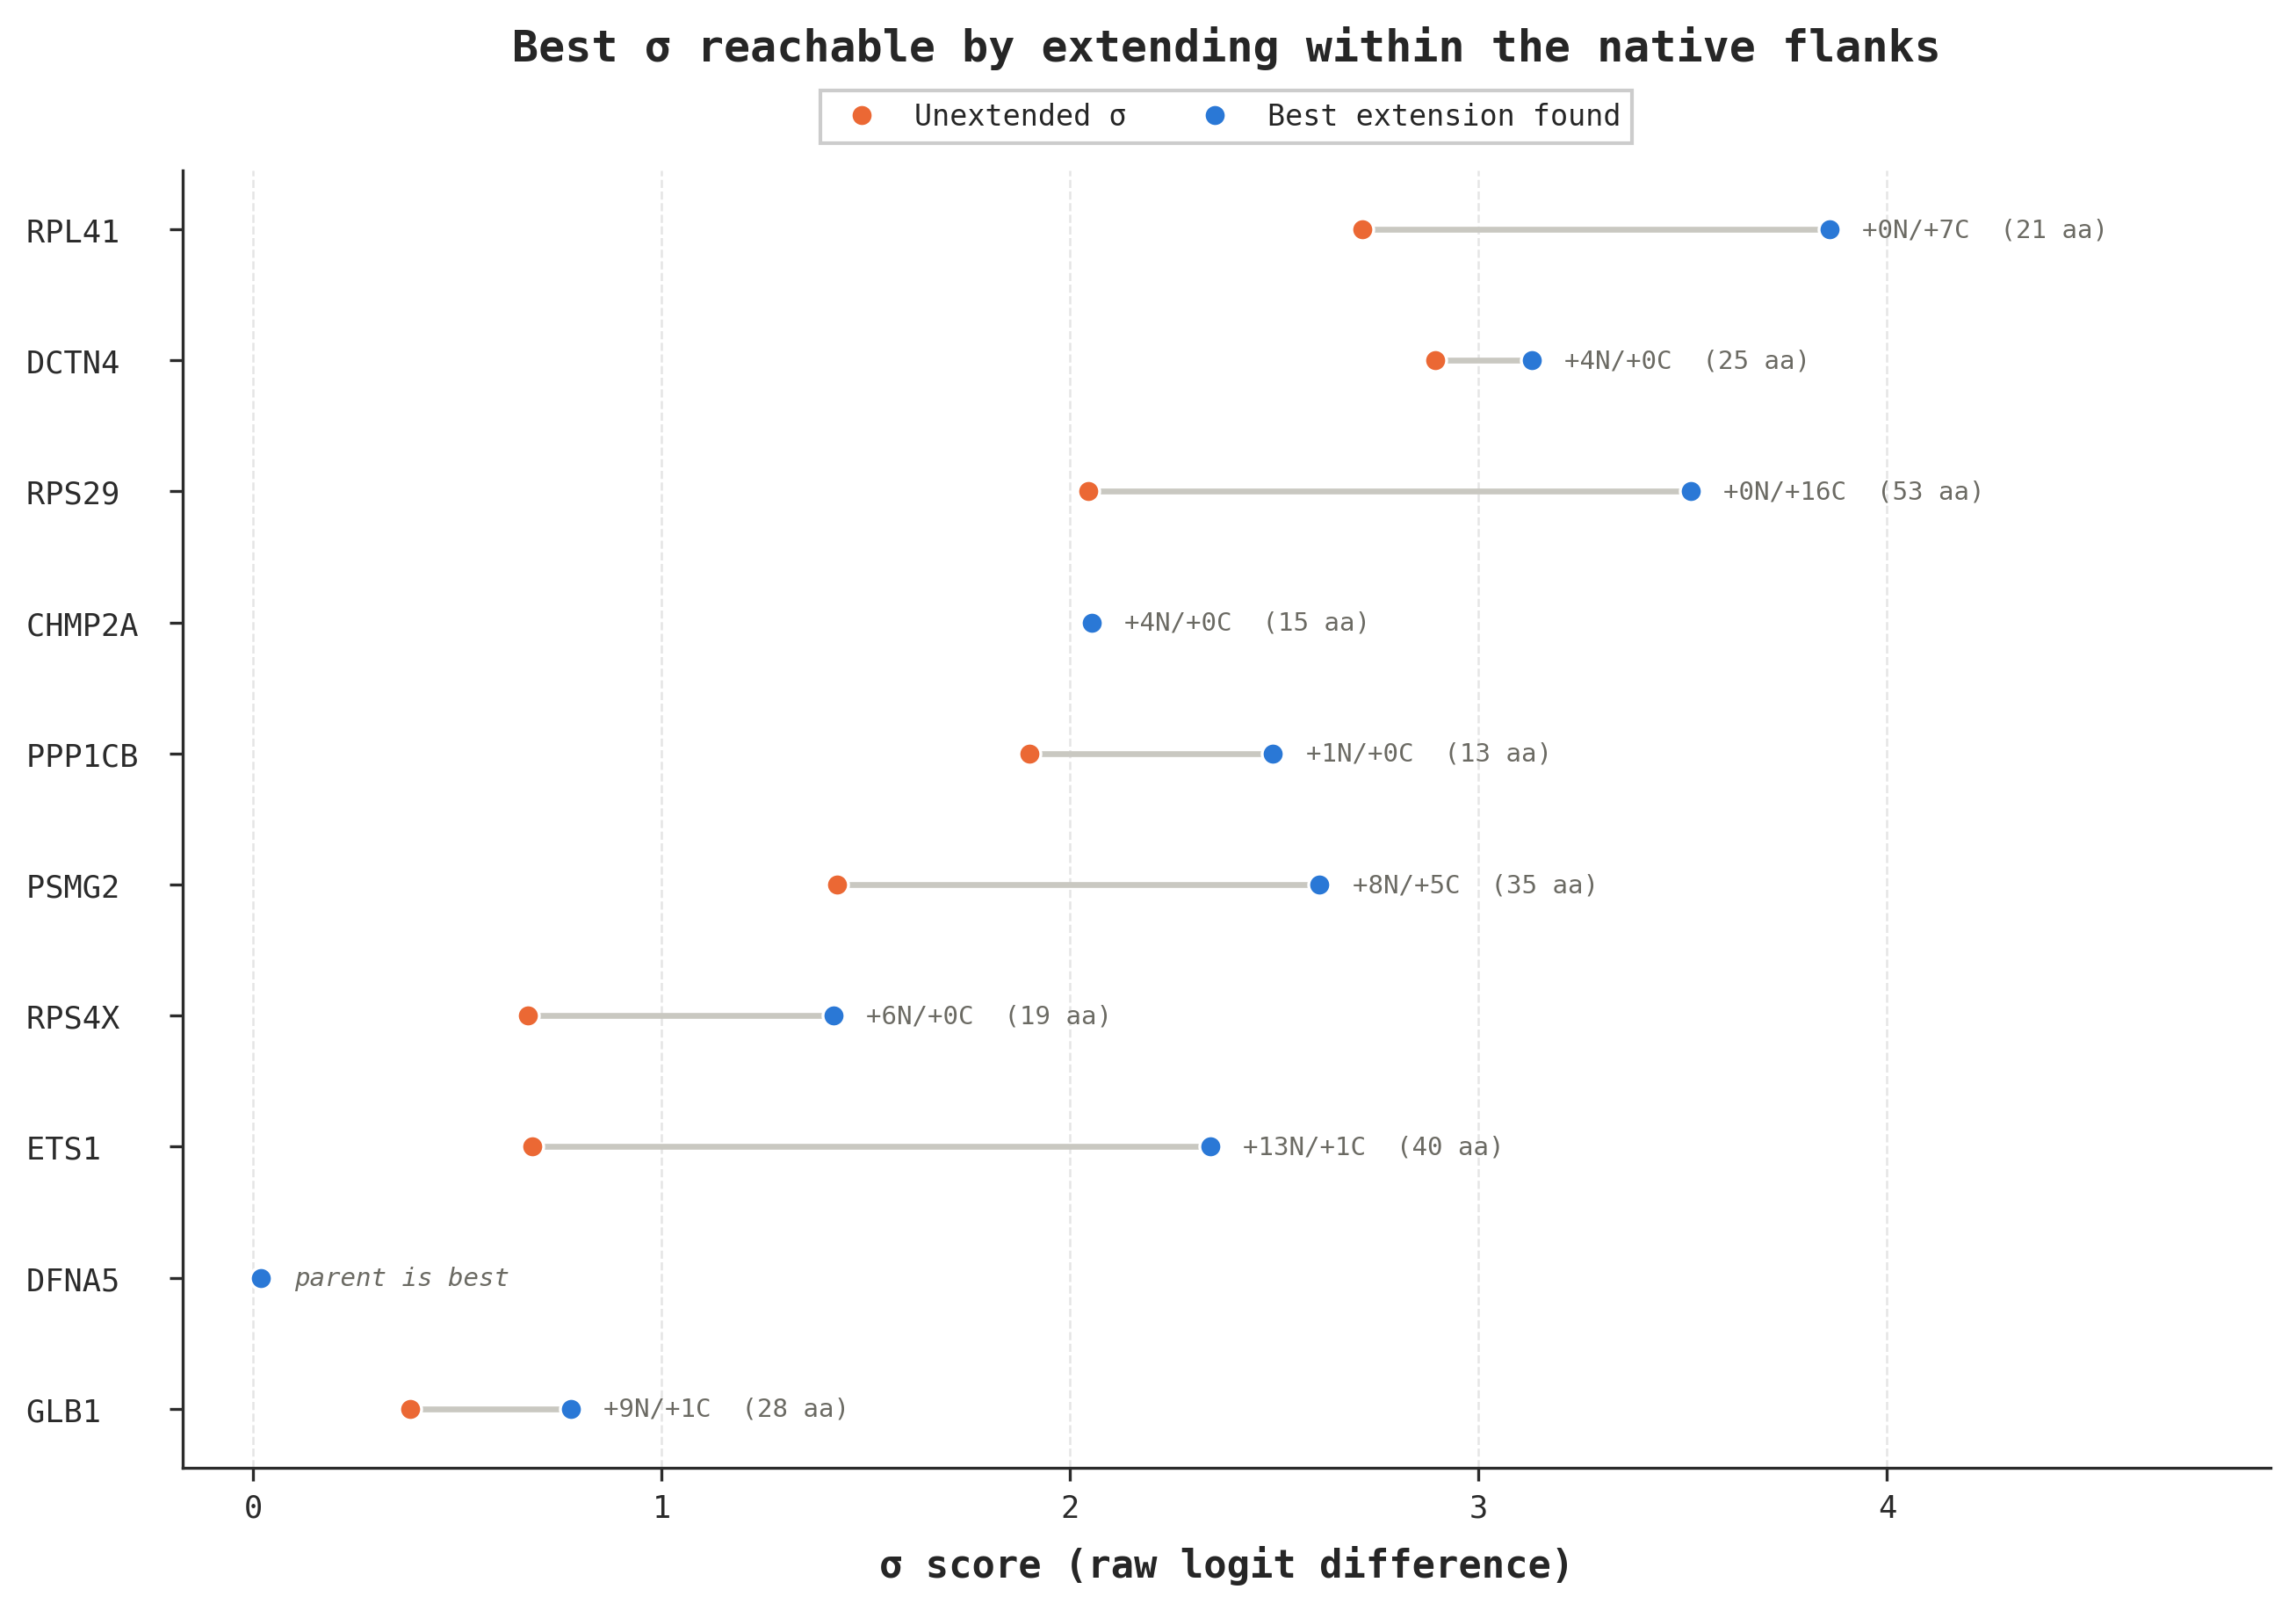

In [40]:
panel = best.loc[PEPTIDE_ORDER[::-1]]
positions = np.arange(len(panel))

figure, axis = plt.subplots(figsize=(8.6, 0.40 * len(panel) + 2.0), dpi=300, layout="constrained")
axis.hlines(positions, panel["parent_sigma"], panel["sigma"], color="#c9c8c1",
            linewidth=1.6, zorder=1)
axis.plot(panel["parent_sigma"], positions, "o", markersize=6, color="#eb6834",
          markeredgecolor="white", markeredgewidth=0.8, zorder=3, linestyle="none",
          label="Unextended σ")
axis.plot(panel["sigma"], positions, "o", markersize=6, color="#2a78d6",
          markeredgecolor="white", markeredgewidth=0.8, zorder=3, linestyle="none",
          label="Best extension found")

for position, row in zip(positions, panel.itertuples()):
    if row.delta_sigma > 1e-9:
        axis.annotate(f"+{row.left_added}N/+{row.right_added}C  ({row.variant_length} aa)",
                      xy=(row.sigma, position), textcoords="offset points", xytext=(9, 0),
                      fontsize=7, color="#6b6a63", va="center")
    else:
        axis.annotate("parent is best", xy=(row.sigma, position), textcoords="offset points",
                      xytext=(9, 0), fontsize=7, color="#6b6a63", va="center", style="italic")

axis.set_yticks(positions)
axis.set_yticklabels([f"{peptide:<7}" for peptide in panel.index])
axis.set_xlim(right=float(panel["sigma"].max()) * 1.28)
axis.set_xlabel("σ score (raw logit difference)", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_title("Best σ reachable by extending within the native flanks",
               fontsize=TITLE_SIZE, fontweight="bold", pad=30)
axis.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, fontsize=8,
            frameon=True, fancybox=False, framealpha=1)
style_axes(axis, grid_axis="x")
plt.show()

## One length axis — both runs together

Truncation and single-terminus extension share a terminus and a baseline, so they share an axis:
negative is the fraction of the native length removed by the deletion run, positive is the
fraction added by the extension run, and zero is the native peptide. Working in fractions rather
than residues keeps the ten on one scale — the deletion run reaches −0.2 and the extension run
+0.5 for every one of them, whatever their length.

The **N panel is mirrored**: its extensions run out to the left and its truncations back to the right, so the two panels together show the peptide growing and shrinking from each of its own ends rather than both sharing one direction.

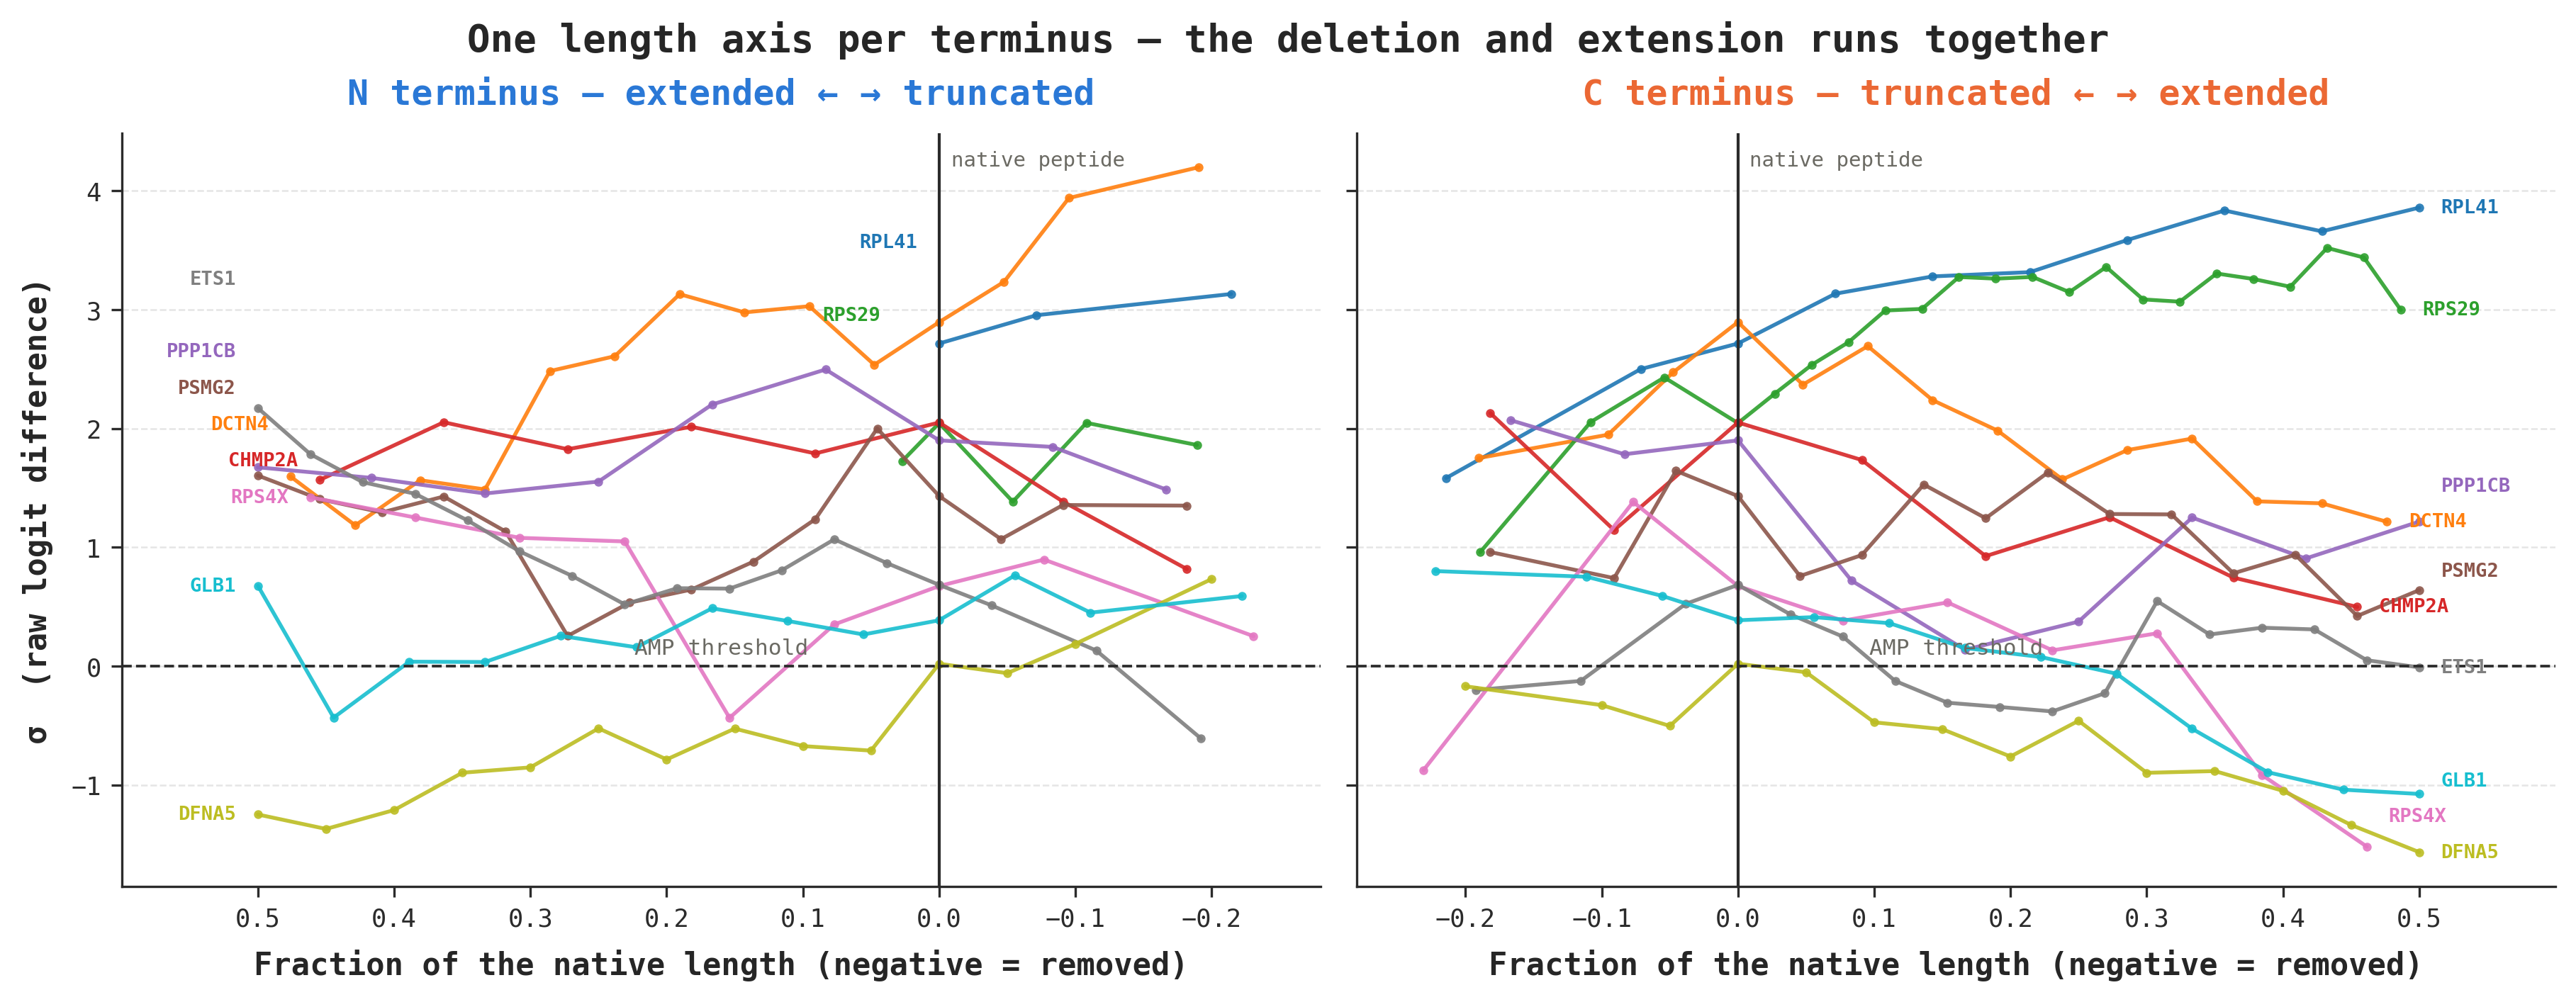

In [41]:
# Both runs fold into the same generated/length_cache, so their unextended parents
# agree and a deletion score can share an axis with an extension score. The axis is
# the fraction of the native length, negative for residues removed; fraction 0 is the
# native peptide and carries its own unperturbed score.
removed = deletion_curves.rename(columns={"terminus": "end"}).copy()
removed["fraction"] = -removed["k"] / removed["parent_length"]
added = pd.concat([
    insertion[insertion["right_added"] == 0].assign(end="N", change=lambda f: f["left_added"]),
    insertion[insertion["left_added"] == 0].assign(end="C", change=lambda f: f["right_added"]),
])
added["fraction"] = added["change"] / added["core_length"]
combined = pd.concat([removed[["parent_id", "end", "fraction", "sigma"]],
                      added[["parent_id", "end", "fraction", "sigma"]]])
combined = combined.drop_duplicates(["parent_id", "end", "fraction"])

figure, axes = plt.subplots(1, 2, figsize=(12.0, 4.6), dpi=300, sharey=True, layout="constrained")
for axis, terminus in zip(axes, TERMINUS_ORDER):
    subset = combined[combined["end"] == terminus]
    gap = (subset["sigma"].max() - subset["sigma"].min()) * 0.055
    ends = {}
    for peptide in PEPTIDE_ORDER:
        line = subset[subset["parent_id"] == peptide].sort_values("fraction")
        axis.plot(line["fraction"], line["sigma"], color=PEPTIDE_COLOR[peptide],
                  linewidth=1.3, marker="o", markersize=3, markeredgewidth=0, alpha=0.9)
        ends[peptide] = (line["fraction"].iloc[-1], line["sigma"].iloc[-1])

    # Lines end at different x, so the ladder runs over every label in the panel:
    # separating them vertically is what stops two labels landing on each other.
    ordered = sorted(ends, key=lambda peptide: ends[peptide][1])
    for peptide, height in zip(ordered, ladder_heights([ends[p][1] for p in ordered], gap)):
        position, value = ends[peptide]
        axis.annotate(peptide, xy=(position, value), xytext=(position + 0.016, height),
                      fontsize=6.5, fontweight="bold", color=PEPTIDE_COLOR[peptide],
                      va="center", ha="right" if terminus == "N" else "left",
                      annotation_clip=False)

    axis.axhline(SIGMA_THRESHOLD, color=SPINE_COLOR, linewidth=0.9, linestyle="--")
    axis.annotate("AMP threshold", xy=(0.5, SIGMA_THRESHOLD), xycoords=("axes fraction", "data"),
                  textcoords="offset points", xytext=(0, 4), ha="center",
                  fontsize=7.5, color="#6b6a63")
    axis.axvline(0.0, color=SPINE_COLOR, linewidth=1.0)
    axis.annotate("native peptide", xy=(0.0, 1.0), xycoords=("data", "axes fraction"),
                  textcoords="offset points", xytext=(4, -11), fontsize=7, color="#6b6a63")
    # Mirrored for N, so the pair reads outwards from the peptide: the N end grows
    # to the left and is cut back to the right, the C end the other way about.
    direction = "extended ← → truncated" if terminus == "N" else "truncated ← → extended"
    axis.set_title(f"{terminus} terminus — {direction}", fontsize=TITLE_SIZE,
                   fontweight="bold", pad=10, color=TERMINUS_COLOR[terminus])
    axis.set_xlabel("Fraction of the native length (negative = removed)", fontsize=LABEL_SIZE,
                    fontweight="bold", labelpad=6)
    axis.set_xticks([-0.2, -0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5])
    span = (-0.28, 0.60)
    axis.set_xlim(*(span[::-1] if terminus == "N" else span))
    style_axes(axis)

axes[0].set_ylabel("σ  (raw logit difference)", fontsize=LABEL_SIZE,
                   fontweight="bold", labelpad=6)
figure.suptitle("One length axis per terminus — the deletion and extension runs together",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### Caveat — the mutation section's baseline is not byte-identical

The three runs do not all fold from the same place. The mutation run reuses
`generated/structures/<gene>.pdb`, folded one peptide at a time; the two length runs fold into
`generated/length_cache` with `fold_batch_size = 16`. ESMFold in fp16 reduces in an order that
depends on the batch dimension, so a batch-folded structure is not bitwise equal to a
single-folded one.

Three of the ten match to within 1e-6 and most of the rest to within a few thousandths. Two move
enough to matter: **DFNA5** by 0.160 σ and **RPL41** by 0.029. DFNA5 is the case to watch, because
it sits within 0.02 of the threshold in the mutation run — a shift of that size is the difference
between an AMP call and no call. So compare Δ values across sections freely, but do not read a
peptide's absolute σ in the mutation section against its σ here.

The deletion and extension runs share the one cache and agree on every parent to 2e-7, which is
CSV float rounding, so the combined axis above is sound.

The figures quoted here describe the runs named at the top of the notebook. Both loader cells reprint the gaps live, so a later run — a refold at a different precision, say — shows its own numbers there even while this text stays as written.

## Overall ranking — σ held and calls kept across all three perturbations

One row per candidate, **ranked by `σ mean after change`**: the score it holds up on average once
mutation, truncation and extension have been applied to it.

| Column | What it is |
|---|---|
| `σ unperturbed` | The native peptide's own σ, nothing done to it. The AMP threshold is 0. |
| `P(AMP) unperturbed` | The same score as a probability, `sigmoid(σ / T)`. The threshold is 0.5. |
| `σ mean after change` | Where it sits on average after perturbation — `σ unperturbed + Δσ mean change`. This is the ranking column. |
| `P(AMP) after change` | That mean σ as a probability. |
| `Δσ mean change` | Mean shift in σ caused by perturbation. Negative is a loss; the three perturbations carry equal weight. |
| `ΔP(AMP) change` | The same loss in probability units. |
| `retention: mutation` | Share of its 4,500 mutants still called AMP, under its **weakest** scheme. |
| `retention: deletion` | Share of its truncations still called AMP, both termini pooled. |
| `retention: insertion` | Share of its whole left × right extension grid still called AMP. |
| `retention: overall` | Mean of the three retentions. |

The two halves of the table answer different questions. **Retention** asks how often a candidate
stays on the AMP side of the line; **σ after change** asks how much margin it keeps. Here the two
mostly agree at the top — RPL41 leads on both, giving up only 0.151 σ and holding 0.973 retention
— but they come apart in the middle: CHMP2A loses the most σ of any candidate (−1.080) yet keeps
0.871 retention, because it starts at 2.05 and has margin to spend, while GLB1 loses only 0.298
and retains 0.615, because it starts at 0.386 and does not.

**DFNA5 is the candidate this ranking rejects.** It starts at σ 0.020 — on the threshold, not
above it in any meaningful sense — and ends at −0.443, the only negative in the table, with 0.252
overall retention and just 0.008 of its extension grid still called AMP.

Each perturbation is averaged on its own before the three are combined, because pooling raw
variants would let the 4,500 mutants drown out the 6 truncations.

Each `P(AMP)` column is `sigmoid(σ / T)` of the σ column beside it, with `T = 0.55893` read from
the checkpoint — the transform **of that mean**, not the mean of the per-variant probabilities.
The two differ because the sigmoid is not linear, and the probability scale compresses hard at the
top: DCTN4 gives up 0.853 σ and only 0.020 of P(AMP), because it starts at 0.994 where there is
almost nothing left to lose. σ is the honest axis for comparing losses; P(AMP) is the readable one
for judging whether a call is safe.

Two limits worth holding in mind:

- **The three probes are not equally severe.** Mutation reaches `p = 0.5` and extension adds up to
  50% per side, but this deletion run stops at `p = 0.2` — at most 7 residues, and only 2 for the
  shortest peptides. It still separates the bottom of the field (DFNA5 0.333, ETS1 0.500,
  RPS4X 0.833) while every other candidate keeps all six truncations, so read that column as a
  floor on fragility rather than a measure of robustness. A deeper deletion run would change this
  ranking.
- **σ here is the length runs' baseline.** For DFNA5 and RPL41 the mutation run folded its own copy
  and started from a slightly different σ (see the caveat above), so their mutation contribution is
  carried over as a Δ rather than as an absolute score.

In [42]:
# Retention = the share of a peptide's variants still called AMP (sigma > 0).
# Mutation is read on its weakest scheme, deletion pools both termini, extension
# uses its whole left x right grid.
worst_scheme = robustness.loc[robustness.groupby("parent_id")["retention_auc"].idxmin()] \
    .set_index("parent_id")["scheme"]
worst_curves = curves[[scheme == worst_scheme[peptide] for peptide, scheme
                       in zip(curves["parent_id"], curves["scheme"])]]

retention = pd.DataFrame({
    "mutation": robustness.groupby("parent_id")["retention_auc"].min(),
    "deletion": deletion_curves.groupby("parent_id")["pred"].mean(),
    "insertion": insertion.groupby("parent_id")["pred"].mean(),
})
# Each perturbation is averaged on its own first, then the three are weighted equally -
# pooling raw variants would make the 4,500 mutants drown the 6 truncations.
delta = pd.DataFrame({
    "mutation": worst_curves.groupby("parent_id")["delta_sigma"].mean(),
    "deletion": deletion_curves.groupby("parent_id")["delta_sigma"].mean(),
    "insertion": insertion.groupby("parent_id")["delta_sigma"].mean(),
})


def prob_amp(sigma):
    """The run's own calibration: P(AMP) = sigmoid(sigma / T), T from the checkpoint."""
    return 1.0 / (1.0 + np.exp(-sigma / TEMPERATURE))


summary = pd.DataFrame({"σ unperturbed": deletion_parents})
summary["σ mean after change"] = summary["σ unperturbed"] + delta.mean(axis=1)
summary["Δσ mean change"] = delta.mean(axis=1)
summary.insert(1, "P(AMP) unperturbed", prob_amp(summary["σ unperturbed"]))
summary.insert(3, "P(AMP) after change", prob_amp(summary["σ mean after change"]))
summary["ΔP(AMP) change"] = summary["P(AMP) after change"] - summary["P(AMP) unperturbed"]
for name in ("mutation", "deletion", "insertion"):
    summary[f"retention: {name}"] = retention[name]
summary["retention: overall"] = retention.mean(axis=1)
summary = summary.sort_values("σ mean after change", ascending=False)
summary.index.name = "candidate"

print("σ columns are the raw logit difference; each P(AMP) column is sigmoid(σ / T) of the σ "
      f"beside it,\nwith T = {TEMPERATURE:.5f} from the checkpoint — the transform of that mean, "
      "not the mean of the\nper-variant probabilities, which differ because the sigmoid is not "
      "linear.")
display(summary.style
        .format({"σ unperturbed": "{:.3f}", "σ mean after change": "{:.3f}",
                 "Δσ mean change": "{:+.3f}", "P(AMP) unperturbed": "{:.3f}",
                 "P(AMP) after change": "{:.3f}", "ΔP(AMP) change": "{:+.3f}",
                 "retention: mutation": "{:.3f}", "retention: deletion": "{:.3f}",
                 "retention: insertion": "{:.3f}", "retention: overall": "{:.3f}"})
        .background_gradient(cmap="YlGnBu", subset=["σ mean after change"])
        .background_gradient(cmap="YlGnBu", subset=["retention: overall"], vmin=0.5, vmax=1.0))

σ columns are the raw logit difference; each P(AMP) column is sigmoid(σ / T) of the σ beside it,
with T = 0.55893 from the checkpoint — the transform of that mean, not the mean of the
per-variant probabilities, which differ because the sigmoid is not linear.


,σ unperturbed,P(AMP) unperturbed,σ mean after change,P(AMP) after change,Δσ mean change,ΔP(AMP) change,retention: mutation,retention: deletion,retention: insertion,retention: overall
candidate,,,,,,,,,,
RPL41,2.715,0.992,2.564,0.990,-0.151,-0.002,0.918,1.000,1.000,0.973
DCTN4,2.895,0.994,2.041,0.975,-0.853,-0.020,0.893,1.000,1.000,0.964
RPS29,2.045,0.975,1.864,0.966,-0.181,-0.009,0.828,1.000,1.000,0.943
PPP1CB,1.900,0.968,0.993,0.855,-0.907,-0.112,0.602,1.000,0.918,0.840
CHMP2A,2.050,0.975,0.970,0.850,-1.080,-0.125,0.641,1.000,0.972,0.871
PSMG2,1.431,0.928,0.822,0.813,-0.609,-0.115,0.524,1.000,0.972,0.832
ETS1,0.683,0.773,0.264,0.616,-0.420,-0.157,0.471,0.500,0.944,0.638
RPS4X,0.674,0.769,0.236,0.604,-0.438,-0.165,0.467,0.833,0.571,0.624
GLB1,0.386,0.666,0.087,0.539,-0.298,-0.127,0.414,1.000,0.430,0.615


## Top ten variants found

Every variant from the two length runs in one pool — 852 extensions and 60 truncations over the
ten candidates, 904 distinct sequences — ranked by σ. The mutation run is **not** in this pool: it
writes per-cell means over 500 replicates rather than the individual mutants, so its rows are not
the same kind of object as these.

| Column | What it is |
|---|---|
| `candidate` | The native peptide this variant came from. |
| `run` | Which sweep produced it, extension or deletion. |
| `what changed` | `+nN/+nC` residues added at each end, or `-kN` / `-kC` residues cut from one end. |
| `length` | The variant's own length in residues. |
| `σ`, `P(AMP)` | Its score, raw and as a probability. |
| `Δσ vs native` | How much better or worse than the peptide it came from. |

The ten are concentrated in three candidates, which is itself the finding: **DCTN4** takes the top
two places by having its first two to four residues *cut away* rather than by growing, **RPL41**
grows into a C-terminal flank that is almost pure lysine and arginine (`…KRKRRKMR`) and the model
rewards every residue of it, and **RPS29** gains the most of any candidate by extending sixteen
residues at the C end. The best variant of each of the ten is in the dumbbell figure above.

As with that figure, this is the maximum over a sweep scored by the model doing the ranking, so
some of the margin at the top is the model's own noise. These are candidates to test, not measured
improvements.

In [43]:
# One row per variant, pooled over the two length runs. Mutation is left out: that run
# writes per-cell means over 500 replicates, not the individual mutants, so its rows
# are not the same kind of object as these.
extensions = insertion[(insertion["left_added"] > 0) | (insertion["right_added"] > 0)].assign(
    change=lambda frame: ["+%dN/+%dC" % pair
                          for pair in zip(frame["left_added"], frame["right_added"])],
    run="extension",
)
truncations = deletion_curves.assign(
    change=lambda frame: ["-%d%s" % pair for pair in zip(frame["k"], frame["terminus"])],
    run="deletion",
)
COLUMNS = ["parent_id", "run", "change", "variant_length", "sequence",
           "sigma", "prob_AMP", "delta_sigma"]
pool = (pd.concat([extensions[COLUMNS], truncations[COLUMNS]])
        .drop_duplicates(["parent_id", "sequence"]))

top_variants = pool.nlargest(10, "sigma").reset_index(drop=True)
top_variants.insert(0, "rank", np.arange(1, len(top_variants) + 1))
top_variants = top_variants.rename(columns={
    "parent_id": "candidate", "change": "what changed", "variant_length": "length",
    "sigma": "σ", "prob_AMP": "P(AMP)", "delta_sigma": "Δσ vs native",
})

leaders = top_variants["candidate"].value_counts()
print(f"Pool: {len(pool)} distinct variants "
      f"({len(extensions)} extensions, {len(truncations)} truncations) over "
      f"{pool['parent_id'].nunique()} candidates.")
print("Top ten are concentrated: " + ", ".join(f"{name} x{count}" for name, count in leaders.items())
      + ". The best variant of each candidate is in the dumbbell above.")
display(top_variants.style.format({"σ": "{:.3f}", "P(AMP)": "{:.4f}", "Δσ vs native": "{:+.3f}"})
        .background_gradient(cmap="YlGnBu", subset=["σ"]).hide(axis="index"))

Pool: 904 distinct variants (852 extensions, 60 truncations) over 10 candidates.
Top ten are concentrated: RPL41 x5, RPS29 x3, DCTN4 x2. The best variant of each candidate is in the dumbbell above.


rank,candidate,run,what changed,length,sequence,σ,P(AMP),Δσ vs native
1,DCTN4,deletion,-4N,17,PRHKHLLIKRSLRCRKC,4.198,0.9995,+1.304
2,DCTN4,deletion,-2N,19,LYPRHKHLLIKRSLRCRKC,3.939,0.9991,+1.045
3,RPL41,extension,+0N/+7C,21,MRAKWRKKRMRRLKRKRRKMR,3.858,0.9990,+1.143
4,RPL41,extension,+0N/+5C,19,MRAKWRKKRMRRLKRKRRK,3.834,0.9990,+1.119
5,RPL41,extension,+0N/+6C,20,MRAKWRKKRMRRLKRKRRKM,3.659,0.9986,+0.944
6,RPL41,extension,+0N/+4C,18,MRAKWRKKRMRRLKRKRR,3.586,0.9984,+0.871
7,RPS29,extension,+0N/+16C,53,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGLNMCRQCFRQYAKDIGFIK,3.519,0.9982,+1.474
8,RPS29,extension,+0N/+17C,54,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGLNMCRQCFRQYAKDIGFIKL,3.438,0.9979,+1.393
9,RPS29,extension,+0N/+10C,47,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGLNMCRQCFRQYAK,3.359,0.9976,+1.314
10,RPL41,extension,+0N/+3C,17,MRAKWRKKRMRRLKRKR,3.315,0.9974,+0.600


## Top robustness candidates — the ones that keep the call everywhere

A candidate qualifies here only if the model still calls it an AMP after **every** perturbation it
was put through. The three sweeps do not support the same test, so the filter is not symmetric:

- **Truncation** and **extension** are deterministic — each (terminus, p) cell and each (N, C) cell
  is one sequence, scored once. "Every variant stays AMP" is therefore a literal test, and is
  applied as one: `pred == 1` for all 6 truncations and for the whole left × right grid.
- **Mutation** is stochastic — 500 random replicates per (scheme, p) cell, 13,500 per peptide. At
  `p = 0.5` under uniform substitution half the residues are replaced at random, so *no* peptide
  keeps 100% of its mutants; the best of the ten is RPL41 at 0.734. A literal all-AMP test on this
  axis selects nobody and says nothing. It is replaced by a floor on the **worst cell**:
  `MUTATION_RETENTION_FLOOR`, the retention a peptide must hold even at its single worst
  (scheme, p) combination.

A floor of 0.5 reads as "even at the harshest dose and the least conservative scheme, a random
mutant is still more likely than not to be called an AMP". Lower the constant to widen the set —
the table below prints every candidate and the three criteria, so what each threshold admits or
rejects is visible rather than hidden.

In [44]:
# Mutation is 500 random replicates per cell, so a literal all-AMP test selects nobody;
# the floor is on the worst (scheme, p) cell a peptide has. The two length sweeps are
# deterministic - one sequence per cell - so there "every variant stays AMP" is literal.
MUTATION_RETENTION_FLOOR = 0.5

# The unextended (0, 0) cell is the native peptide, not an extension of it.
extension_variants = insertion[(insertion["left_added"] > 0) | (insertion["right_added"] > 0)]

criteria = pd.DataFrame({
    "native σ": parents.set_index("parent_id")["parent_sigma"],
    "mutation: worst cell retention": curves.groupby("parent_id")["retention"].min(),
    "truncation: variants kept": deletion_curves.groupby("parent_id")["pred"].sum(),
    "truncation: variants": deletion_curves.groupby("parent_id")["pred"].size(),
    "extension: variants kept": extension_variants.groupby("parent_id")["pred"].sum(),
    "extension: variants": extension_variants.groupby("parent_id")["pred"].size(),
})
criteria["passes mutation"] = criteria["mutation: worst cell retention"] >= MUTATION_RETENTION_FLOOR
criteria["passes truncation"] = criteria["truncation: variants kept"] == criteria["truncation: variants"]
criteria["passes extension"] = criteria["extension: variants kept"] == criteria["extension: variants"]
criteria["robust"] = (criteria["passes mutation"] & criteria["passes truncation"]
                      & criteria["passes extension"])
criteria = criteria.sort_values(["robust", "mutation: worst cell retention"], ascending=False)

ROBUST = criteria.index[criteria["robust"]].tolist()
print(f"{len(ROBUST)} of {len(criteria)} candidates keep the AMP call under every perturbation "
      f"(mutation floor {MUTATION_RETENTION_FLOOR:g}): {', '.join(ROBUST)}")
for name, column in (("mutation", "passes mutation"), ("truncation", "passes truncation"),
                     ("extension", "passes extension")):
    failed = criteria.index[~criteria[column]].tolist()
    print(f"  rejected by {name:<11}: {', '.join(failed) if failed else 'none'}")

shown = criteria.copy()
shown["truncation kept"] = (shown["truncation: variants kept"].astype(int).astype(str)
                            + " / " + shown["truncation: variants"].astype(int).astype(str))
shown["extension kept"] = (shown["extension: variants kept"].astype(int).astype(str)
                           + " / " + shown["extension: variants"].astype(int).astype(str))
shown["robust"] = np.where(shown["robust"], "yes", "no")
shown.index.name = "candidate"
display(shown[["native σ", "mutation: worst cell retention", "truncation kept",
               "extension kept", "robust"]]
        .style.format({"native σ": "{:.3f}", "mutation: worst cell retention": "{:.3f}"})
        .apply(lambda column: np.where(shown["robust"] == "yes",
                                       "font-weight: bold", ""), axis=0))

3 of 10 candidates keep the AMP call under every perturbation (mutation floor 0.5): RPL41, DCTN4, RPS29
  rejected by mutation   : RPS4X, CHMP2A, PPP1CB, PSMG2, GLB1, DFNA5, ETS1
  rejected by truncation : RPS4X, DFNA5, ETS1
  rejected by extension  : RPS4X, CHMP2A, PPP1CB, PSMG2, GLB1, DFNA5, ETS1


,native σ,mutation: worst cell retention,truncation kept,extension kept,robust
candidate,,,,,
RPL41,2.744,0.734,6 / 6,7 / 7,yes
DCTN4,2.895,0.586,6 / 6,120 / 120,yes
RPS29,2.045,0.542,6 / 6,37 / 37,yes
RPS4X,0.674,0.352,5 / 6,27 / 48,no
CHMP2A,2.050,0.332,6 / 6,34 / 35,no
PPP1CB,1.900,0.306,6 / 6,44 / 48,no
PSMG2,1.431,0.298,6 / 6,139 / 143,no
GLB1,0.386,0.292,6 / 6,42 / 99,no
DFNA5,0.180,0.282,2 / 6,0 / 120,no


### Ranked by mean retained σ, one table per variation type

The survivors above all keep the call everywhere, so the AMP-call fraction cannot separate them —
every one of them scores 1.0 on the deterministic axes by construction. What still separates them
is **how much σ they hold on to**, which is why each table below ranks on absolute σ rather than
on a Δ.

`mean σ` is the unweighted mean over that variation's variants, and `mean σ / native σ` is the
fraction of the unperturbed score still standing. The two disagree on purpose: a candidate can
hold a high mean σ because it started high, or a high fraction because it gave up little, and the
pair makes which one visible. **A ratio above 1 means the perturbation raises the score on
average** — extension does exactly that for RPL41 and RPS29, so in that table the column reads as
gain rather than loss.

**`worst scheme`** names the substitution scheme whose mutants hold the least σ on average for
that peptide — the one it tolerates worst of the three. The schemes differ in how freely they
substitute: `physicochemical` preserves charge, polarity and aromaticity class (and never touches
P, C or G), `blosum62` samples a softmax over the BLOSUM62 row, and `uniform` picks any of the
other 19 residues evenly. Uniform is the least conservative and is the worst scheme for nine of
the ten candidates; RPS29 is the exception, where `blosum62` costs it slightly more. Showing the
worst scheme's own mean beside the overall one stops a good average from hiding a scheme the
peptide copes with far less well.

The three tables do not agree on an order, which is the reason for splitting them: DCTN4 is second
under mutation, last under extension and first under truncation. A single combined robustness
score would have averaged that structure away.

What counts as a variant differs per table, and each is the same population the filter tested:

- **Mutation** — all 27 (scheme, p) cells, each the mean over 500 replicates. Since every cell
  carries the same 500, the mean over cells is the mean over all 13,500 mutants.
- **Truncation** — the 6 single-terminus truncations, N and C pooled.
- **Extension** — the whole left × right grid with the unextended (0, 0) cell removed, since that
  cell is the native peptide rather than an extension of it. The grids are very different sizes
  (RPL41 has 7 variants, DCTN4 120), so these means rest on unequal evidence.

In [45]:
def retained_sigma(frame: pd.DataFrame, value: str, label: str,
                   worst: pd.DataFrame | None = None) -> pd.DataFrame:
    """Mean absolute sigma over a variation's variants, against the native score."""
    table = pd.DataFrame({
        "native σ": parents.set_index("parent_id")["parent_sigma"],
        f"mean σ ({label})": frame.groupby("parent_id")[value].mean(),
        "variants": frame.groupby("parent_id")[value].size(),
    }).loc[ROBUST]
    if worst is not None:
        table["worst scheme"] = worst["scheme"].loc[ROBUST]
        table["worst scheme mean σ"] = worst["mean_sigma"].loc[ROBUST]
    # Fraction of the native score still standing. Above 1 means the perturbation
    # raises it on average, which extension does.
    table["mean σ / native σ"] = table[f"mean σ ({label})"] / table["native σ"]
    table = table.sort_values(f"mean σ ({label})", ascending=False)
    table.insert(0, "rank", np.arange(1, len(table) + 1))
    table.index.name = "candidate"
    return table


# For each peptide, the substitution scheme whose mutants hold the least sigma on
# average - the one it tolerates worst. A high mutation average cannot then hide a
# scheme the peptide copes with far less well than the other two.
by_scheme = curves.groupby(["parent_id", "scheme"])["mean_sigma"].mean().unstack()
worst_scheme = pd.DataFrame({"scheme": by_scheme.idxmin(axis=1),
                             "mean_sigma": by_scheme.min(axis=1)})

TABLES = [
    ("Mutation", retained_sigma(curves, "mean_sigma", "mutation", worst_scheme)),
    ("Extension", retained_sigma(extension_variants, "sigma", "extension")),
    ("Truncation", retained_sigma(deletion_curves, "sigma", "truncation")),
]

for name, table in TABLES:
    print(f"\n{name} — {len(table)} robust candidate(s), ranked by mean retained σ")
    # One combined dict: chaining .format() twice resets the earlier formatters.
    formats = {column: "{:.3f}" for column in table.columns
               if pd.api.types.is_numeric_dtype(table[column]) and column != "rank"}
    formats["variants"] = "{:,.0f}"
    display(table.style.format(formats)
            .background_gradient(cmap="YlGnBu",
                                 subset=[c for c in table.columns if c.startswith("mean σ (")]))


Mutation — 3 robust candidate(s), ranked by mean retained σ


,rank,native σ,mean σ (mutation),variants,worst scheme,worst scheme mean σ,mean σ / native σ
candidate,,,,,,,
RPL41,1,2.744,2.220,27,uniform,1.694,0.809
DCTN4,2,2.895,1.962,27,uniform,1.481,0.678
RPS29,3,2.045,1.292,27,blosum62,0.877,0.632



Extension — 3 robust candidate(s), ranked by mean retained σ


,rank,native σ,mean σ (extension),variants,mean σ / native σ
candidate,,,,,
RPL41,1,2.744,3.524,7,1.284
RPS29,2,2.045,2.951,37,1.443
DCTN4,3,2.895,1.709,120,0.591



Truncation — 3 robust candidate(s), ranked by mean retained σ


,rank,native σ,mean σ (truncation),variants,mean σ / native σ
candidate,,,,,
DCTN4,1,2.895,2.924,6,1.010
RPL41,2,2.744,2.603,6,0.949
RPS29,3,2.045,1.789,6,0.875


## Membrane permeability versus σ

The reference paper tested these same ten peptides for membrane permeabilisation against five
bacterial species at four concentrations and published the result only as a grayscale heatmap.
`data/proteome_sanity_test/membrane_permeability.csv` carries those values, each cell recovered
from its gray level against its own panel's colorbar by `tmp/extract_permeability_heatmap.py`.
The five panels calibrate independently and agree closely (slope 0.488–0.505, intercept
123.0–123.8, residuals under 1), and no cell needed clipping — but these are still numbers read
off a figure. Treat them as good to a few percent, not as assay output.

σ comes from the **proteome sanity test** rather than from this notebook's three perturbation
runs: same checkpoint, same `fitting = "temperature"`, pinned by run id the same way. Note that
`data/proteome_sanity_test/results/runs/` also holds a `whole-protein-` run of the same
timestamp, scoring these peptides as excised from a fold of their full-length parent; this
section deliberately uses the segment-alone run, whose σ is the same number the mutation run
took as its parent baseline, and the loader checks that.

The CSV also holds LK20 (the synthetic positive control) and four low-score controls under
`group`. Everything below keeps the notebook's scope and uses only the ten candidates.

In [46]:
from scipy.stats import pearsonr, spearmanr

# Permeability digitised from the reference figure; see the section note above for how.
PERMEABILITY_CSV = ROOT / "data" / "proteome_sanity_test" / "membrane_permeability.csv"
# Pinned, not newest-on-disk, like RUN_IDS above. The sibling "whole-protein-" run of the
# same timestamp folds each peptide inside its parent protein and is a different experiment.
SANITY_RUN_ID = "2026-11-18_10-42"
SANITY_CSV = (ROOT / "data" / "proteome_sanity_test" / "results" / "runs"
              / SANITY_RUN_ID / "sequence_predictions.csv")

permeability = pd.read_csv(PERMEABILITY_CSV, keep_default_na=False)
sanity = pd.read_csv(SANITY_CSV)

permeability = permeability[permeability["group"] == "PDDP"]
permeability = permeability.merge(sanity[["id", "sigma", "p_amp"]], on="id")

SPECIES_ORDER = ["P. aeruginosa", "S. enterica", "E. coli", "M. luteus", "S. haemolyticus"]
DOSE_ORDER = sorted(permeability["concentration_uM"].unique(), reverse=True)
# Ordered, so the ramp reads as a dose rather than as four unrelated categories.
DOSE_COLOR = dict(zip(DOSE_ORDER, plt.get_cmap("viridis")(np.linspace(0.05, 0.62, len(DOSE_ORDER)))))

# One row per species and dose, over the ten peptides: the least-squares fit the panels
# draw and the correlations they annotate, computed once here and read back below.
fits = []
for species in SPECIES_ORDER:
    for dose in DOSE_ORDER:
        subset = permeability[(permeability["bacteria"] == species)
                              & (permeability["concentration_uM"] == dose)]
        slope, intercept = np.polyfit(subset["sigma"], subset["permeability"], 1)
        rho, rho_p = spearmanr(subset["sigma"], subset["permeability"])
        r, r_p = pearsonr(subset["sigma"], subset["permeability"])
        fits.append({"bacteria": species, "dose": dose, "slope": slope, "intercept": intercept,
                     "r": r, "r_p": r_p, "rho": rho, "rho_p": rho_p})
agreement = pd.DataFrame(fits).set_index(["bacteria", "dose"])

# The sanity run and the mutation run score the same ten peptides off the same checkpoint
# and the same segment-alone structures, so their sigma has to agree.
measured = permeability.drop_duplicates("id").set_index("id")["sigma"]
baseline = parents.set_index("parent_id")["parent_sigma"]

print("Sigma run: ", SANITY_RUN_ID)
print(f"peptides:   {measured.size}   species: {len(SPECIES_ORDER)}"
      f"   doses: {', '.join(f'{dose:g}' for dose in DOSE_ORDER)} µM")
print(f"sigma:       {measured.min():.2f} to {measured.max():.2f}"
      f"   vs the mutation run's parents: max |difference| = {(measured - baseline).abs().max():.1e}")
print(f"permeability {permeability['permeability'].min():.0f}% to "
      f"{permeability['permeability'].max():.0f}%   ({len(permeability)} rows)")

Sigma run:  2026-11-18_10-42
peptides:   10   species: 5   doses: 5, 2.5, 1.25, 0.625 µM
sigma:       0.18 to 2.89   vs the mutation run's parents: max |difference| = 4.8e-07
permeability 0% to 99%   (200 rows)


### Permeability versus σ — one panel per species

σ is one number per peptide, so each dose contributes ten points spread along x. The coloured
line through each dose is its ordinary least-squares fit on those ten points, so its tilt is
the sign and size of the relationship at that concentration. If σ predicted permeabilisation
the lines would slope up.

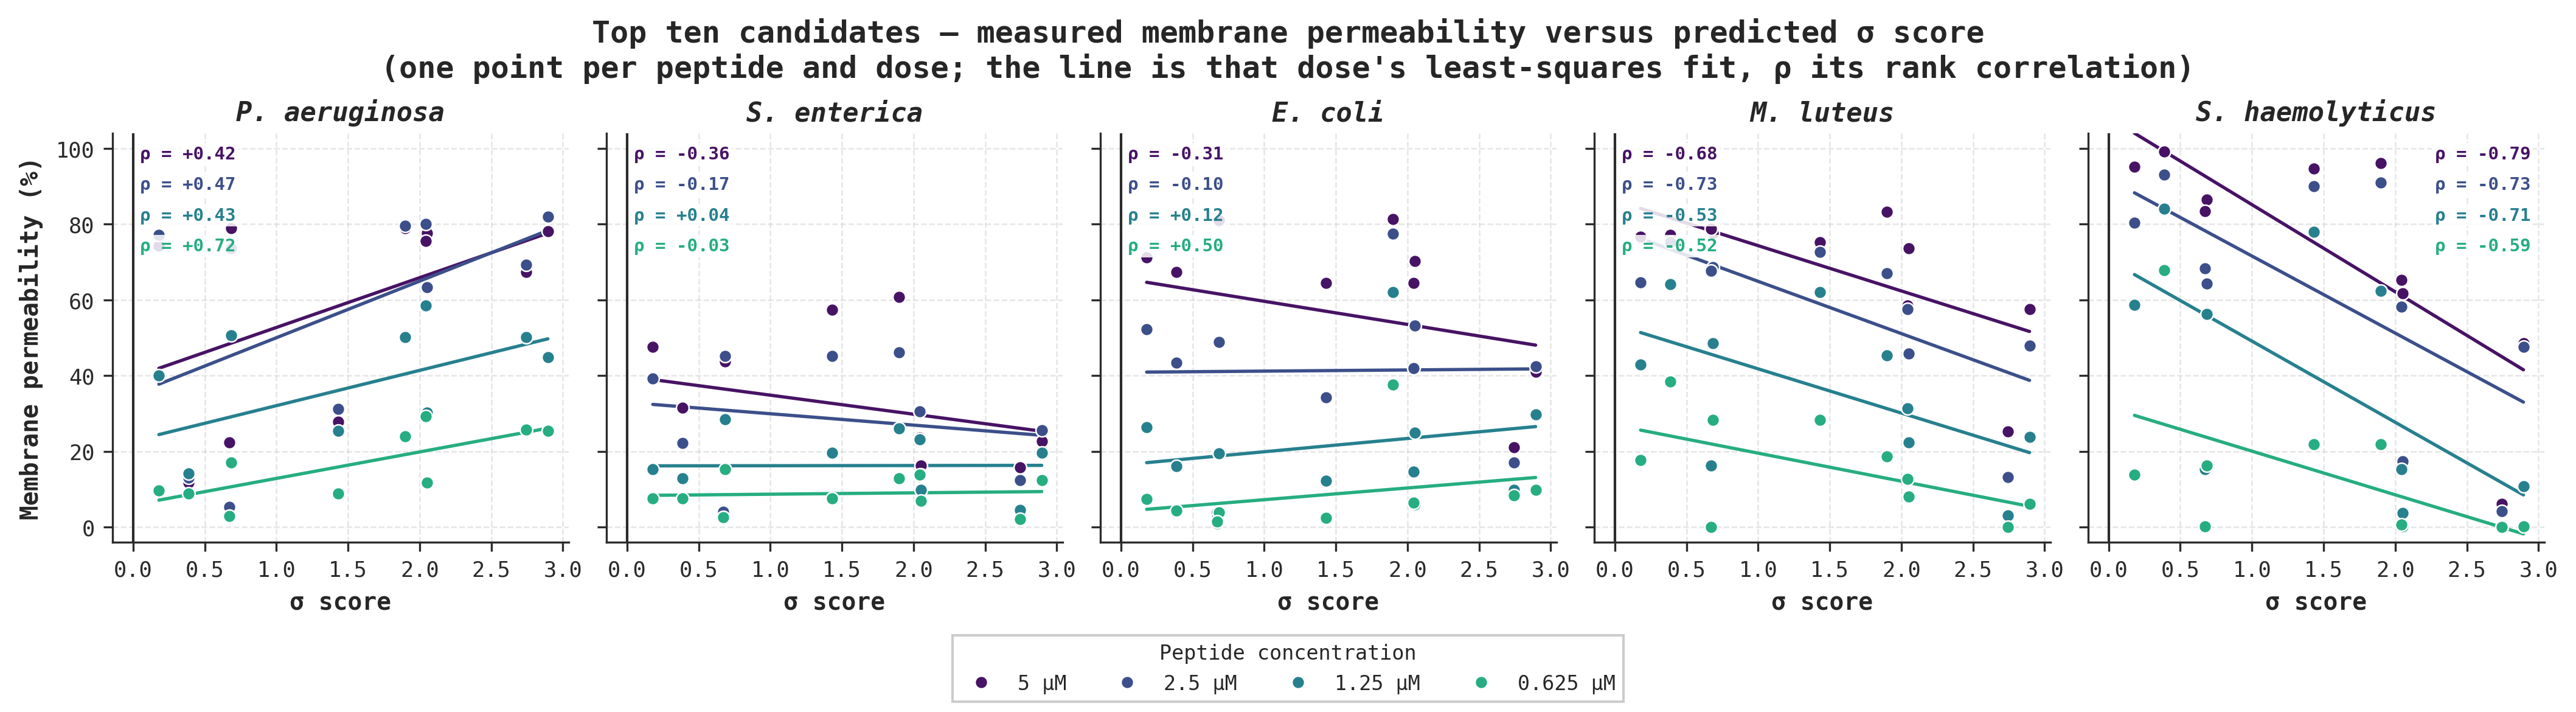

In [47]:
figure, axes = plt.subplots(1, len(SPECIES_ORDER), figsize=(14.0, 3.8), dpi=300,
                            sharex=True, sharey=True, layout="constrained")
# Every panel holds the same ten sigma, so one span draws every fit.
SIGMA_SPAN = np.array([permeability["sigma"].min(), permeability["sigma"].max()])

for axis, species in zip(axes, SPECIES_ORDER):
    frame = permeability[permeability["bacteria"] == species]
    for dose in DOSE_ORDER:
        subset = frame[frame["concentration_uM"] == dose]
        fit = agreement.loc[(species, dose)]
        axis.plot(SIGMA_SPAN, fit["slope"] * SIGMA_SPAN + fit["intercept"],
                  color=DOSE_COLOR[dose], linewidth=1.3, zorder=2)
        axis.plot(subset["sigma"], subset["permeability"], "o", markersize=5,
                  color=DOSE_COLOR[dose], markeredgecolor="white", markeredgewidth=0.6,
                  linestyle="none", zorder=3, label=f"{dose:g} µM")
    # Put the block over whichever half of the panel the points leave lower, and give
    # each line its own backing so it stays legible over a line or a marker.
    middle = SIGMA_SPAN.mean()
    on_left = (frame.loc[frame["sigma"] < middle, "permeability"].max()
               < frame.loc[frame["sigma"] >= middle, "permeability"].max())
    for index, dose in enumerate(DOSE_ORDER):
        axis.annotate(f"ρ = {agreement.loc[(species, dose), 'rho']:+.2f}",
                      xy=(0.06 if on_left else 0.97, 0.97 - 0.075 * index),
                      xycoords="axes fraction", ha="left" if on_left else "right",
                      va="top", fontsize=7, fontweight="bold", color=DOSE_COLOR[dose],
                      bbox=dict(boxstyle="square,pad=0.15", facecolor="white",
                                edgecolor="none", alpha=0.85))
    axis.axvline(SIGMA_THRESHOLD, color=SPINE_COLOR, linewidth=1.0)
    axis.set_title(species, fontsize=LABEL_SIZE, fontstyle="italic", fontweight="bold", pad=5)
    axis.set_xlabel("σ score", fontsize=9.5, fontweight="bold", labelpad=4)
    style_axes(axis, grid_axis="both")

axes[0].set_ylabel("Membrane permeability (%)", fontsize=9.5, fontweight="bold", labelpad=5)
axes[0].set_ylim(-4, 104)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="outside lower center", ncol=len(DOSE_ORDER),
              fontsize=8, frameon=True, fancybox=False, framealpha=1,
              title="Peptide concentration", title_fontsize=8)
figure.suptitle("Top ten candidates — measured membrane permeability versus predicted σ score\n"
                "(one point per peptide and dose; the line is that dose's least-squares fit, "
                "ρ its rank correlation)", fontsize=TITLE_SIZE, fontweight="bold")
plt.show()

### One panel per species and dose

The same twenty fits pulled apart, so no dose hides behind another: rows are species, columns
are concentration, and each panel carries its own ten points, its least-squares line and both
correlations over those ten. Pearson *r* measures the line the panel draws; Spearman ρ measures
the ranking, which is what σ is actually being asked for. The two agree in sign except where
both sit near zero — *S. enterica* at 0.625 µM and *E. coli* at 2.5 µM — where neither is
distinguishable from no relationship at all.

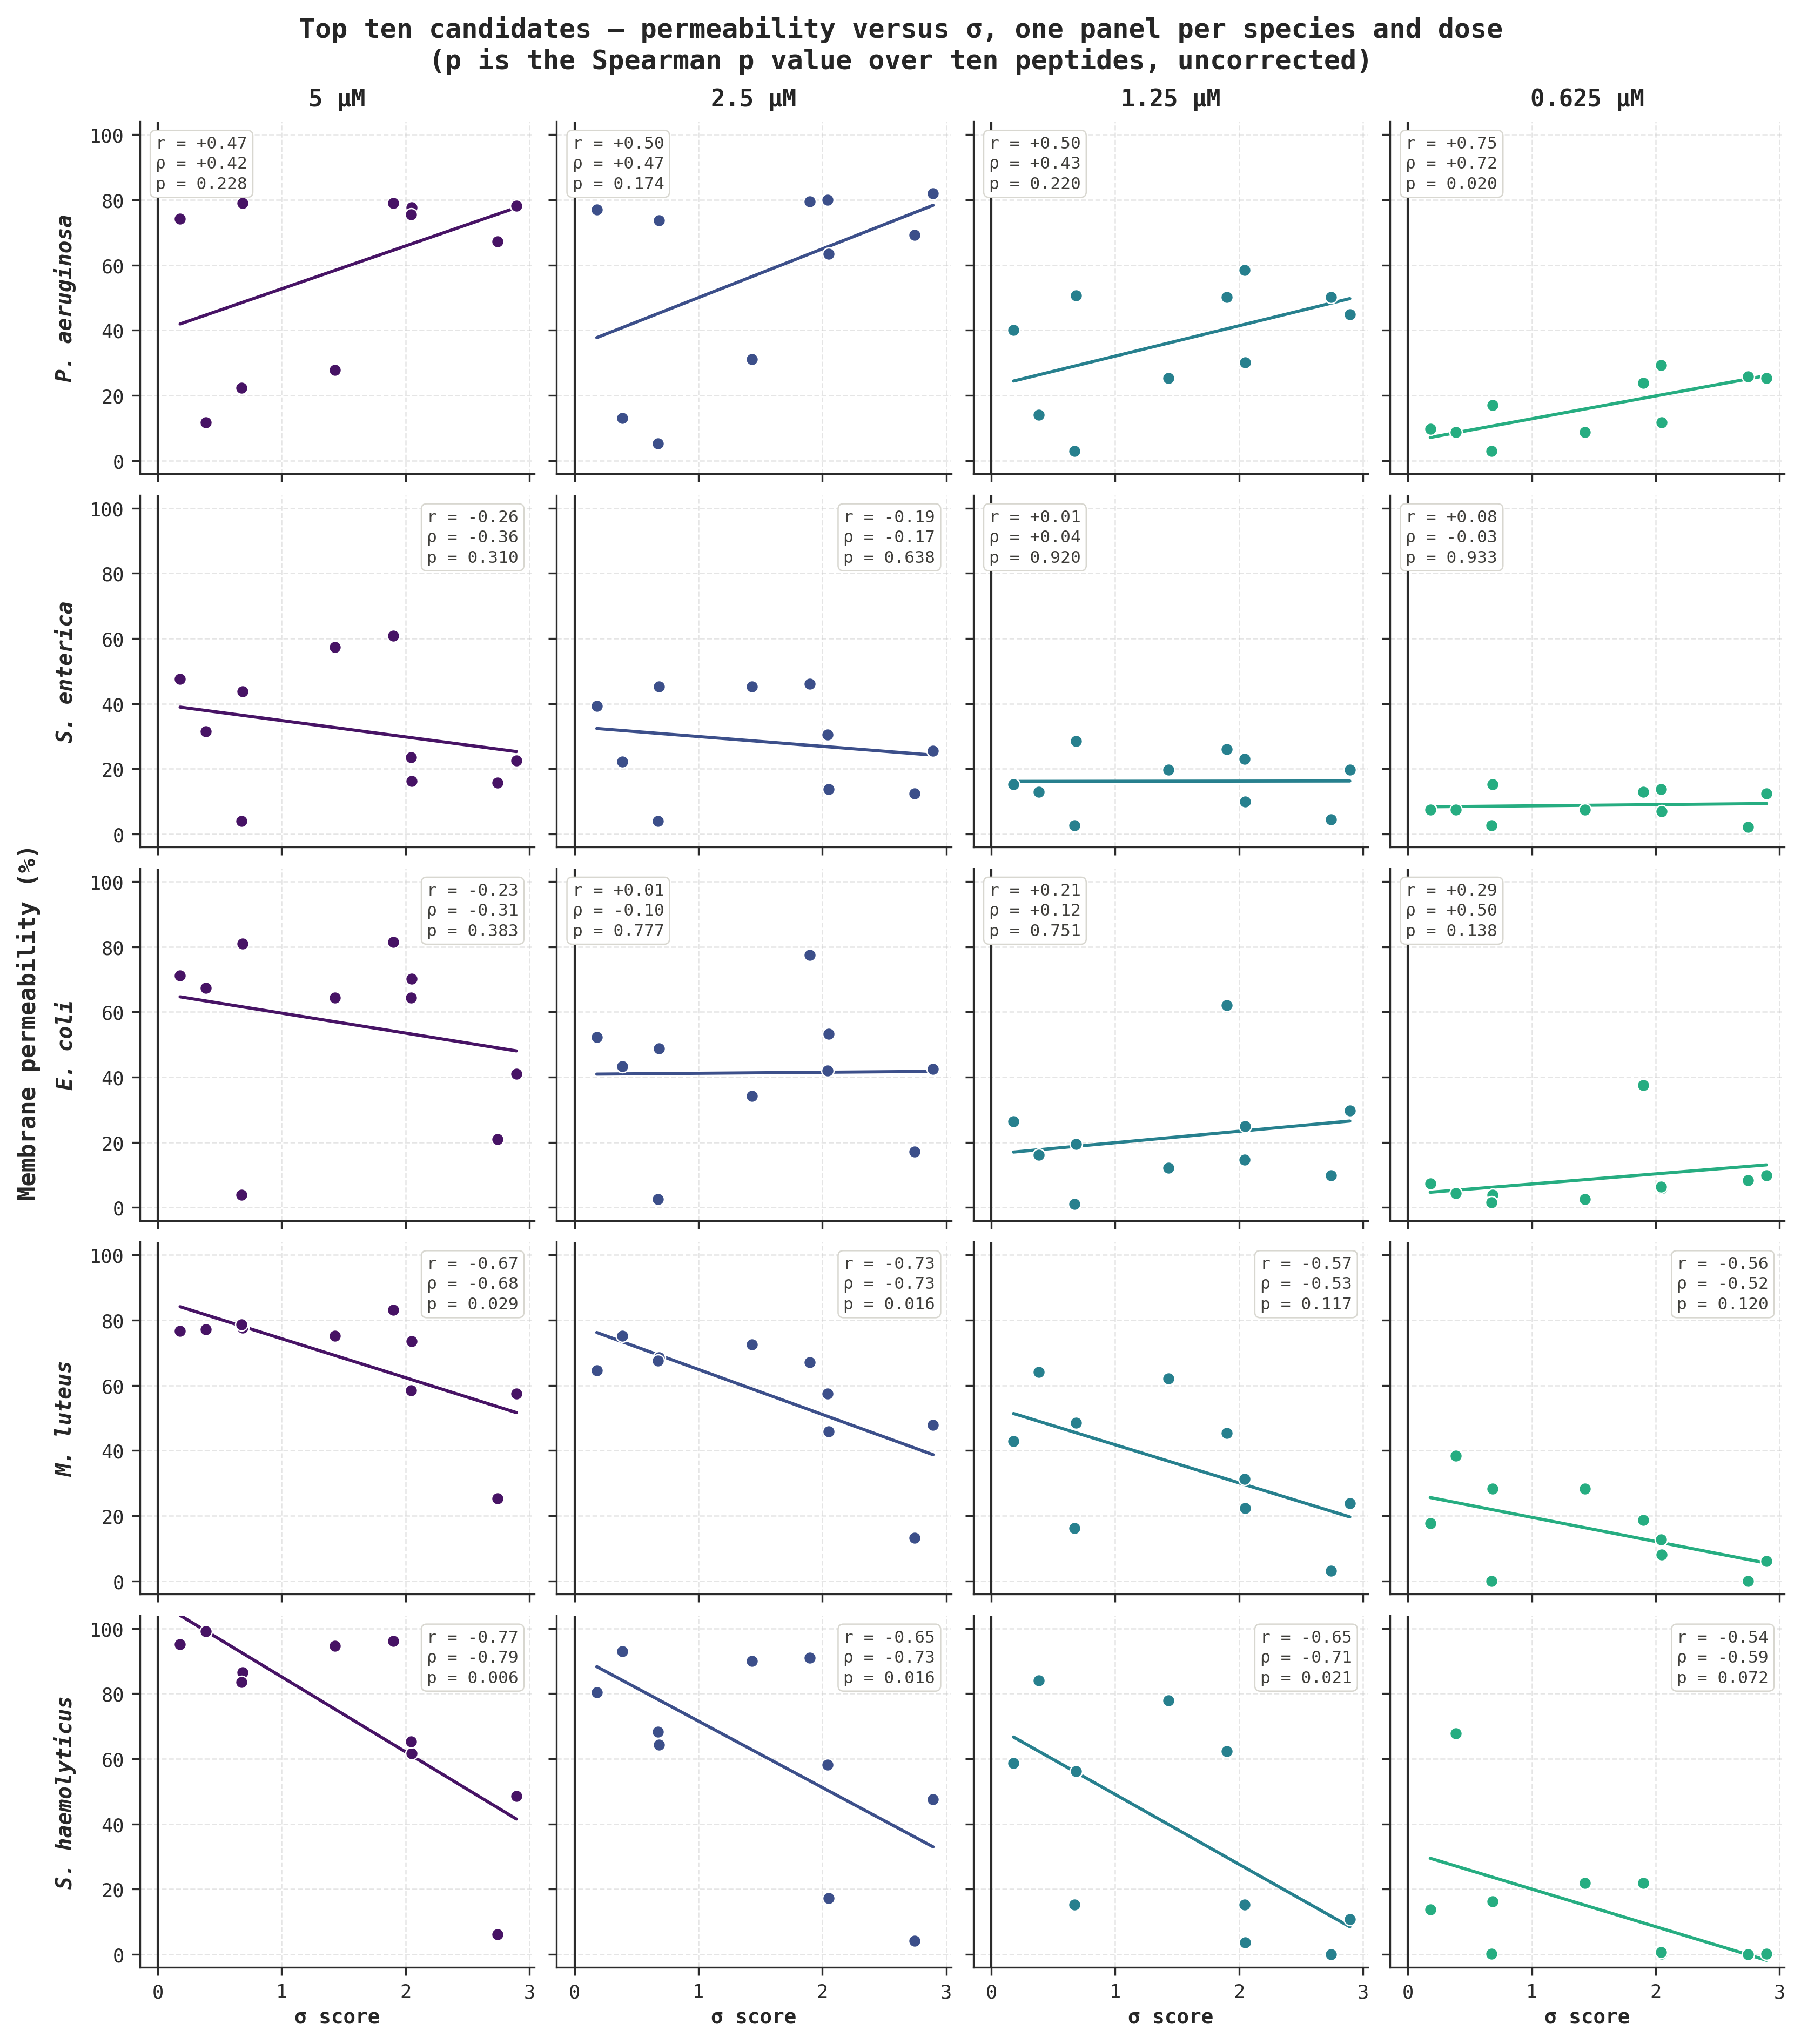

In [48]:
figure, axes = plt.subplots(len(SPECIES_ORDER), len(DOSE_ORDER), figsize=(11.0, 12.5),
                            dpi=300, sharex=True, sharey=True, layout="constrained")
for row, species in enumerate(SPECIES_ORDER):
    for column, dose in enumerate(DOSE_ORDER):
        axis = axes[row, column]
        subset = permeability[(permeability["bacteria"] == species)
                              & (permeability["concentration_uM"] == dose)]
        fit = agreement.loc[(species, dose)]
        axis.plot(SIGMA_SPAN, fit["slope"] * SIGMA_SPAN + fit["intercept"],
                  color=DOSE_COLOR[dose], linewidth=1.4, zorder=2)
        axis.plot(subset["sigma"], subset["permeability"], "o", markersize=5.5,
                  color=DOSE_COLOR[dose], markeredgecolor="white", markeredgewidth=0.6,
                  linestyle="none", zorder=3)
        axis.axvline(SIGMA_THRESHOLD, color=SPINE_COLOR, linewidth=1.0)
        rising = fit["slope"] > 0
        axis.annotate(f"r = {fit['r']:+.2f}\nρ = {fit['rho']:+.2f}\np = {fit['rho_p']:.3f}",
                      xy=(0.04 if rising else 0.96, 0.96), xycoords="axes fraction",
                      ha="left" if rising else "right", va="top", fontsize=7.5,
                      color="#3f3e3a", linespacing=1.35,
                      bbox=dict(boxstyle="round,pad=0.32", facecolor="white",
                                edgecolor="#d8d7d0", linewidth=0.6))
        if row == 0:
            axis.set_title(f"{dose:g} µM", fontsize=LABEL_SIZE, fontweight="bold", pad=7)
        if column == 0:
            axis.set_ylabel(species, fontsize=9.5, fontstyle="italic",
                            fontweight="bold", labelpad=6)
        if row == len(SPECIES_ORDER) - 1:
            axis.set_xlabel("σ score", fontsize=9, fontweight="bold", labelpad=3)
        style_axes(axis, grid_axis="both")

axes[0, 0].set_ylim(-4, 104)
figure.supylabel("Membrane permeability (%)", fontsize=LABEL_SIZE, fontweight="bold")
figure.suptitle("Top ten candidates — permeability versus σ, one panel per species and dose\n"
                "(p is the Spearman p value over ten peptides, uncorrected)",
                fontsize=TITLE_SIZE, fontweight="bold")
plt.show()

### Rank agreement between σ and permeability

The same correlations as a table, over the ten peptides, one coefficient per species and dose.
The sign is not consistent: σ ranks permeabilisation positively in *P. aeruginosa* and
negatively in the two Gram-positives, where the correlation is strongest. At n = 10 and twenty
uncorrected tests none of this is conclusive on its own, but the direction is stable across all
four doses within a species, which a sampling accident would not be. On this evidence σ is not
ranking membrane permeabilisation of these species — worth holding against the σ ordering the
three perturbation sections rank candidates by.

In [49]:
for value, label in (("r", "Pearson r"), ("rho", "Spearman rho"),
                     ("rho_p", "Spearman p value (uncorrected)")):
    print(label)
    print(agreement[value].unstack("dose").loc[SPECIES_ORDER, DOSE_ORDER]
          .round(3).to_string(), end="\n\n")
print("peptides by sigma: " + ", ".join(measured.sort_values(ascending=False).index))

Pearson r
dose             5.000  2.500  1.250  0.625
bacteria                                   
P. aeruginosa    0.473  0.496  0.504  0.745
S. enterica     -0.256 -0.192  0.005  0.078
E. coli         -0.229  0.015  0.207  0.289
M. luteus       -0.674 -0.727 -0.571 -0.561
S. haemolyticus -0.769 -0.646 -0.646 -0.536

Spearman rho
dose             5.000  2.500  1.250  0.625
bacteria                                   
P. aeruginosa    0.419  0.467  0.426  0.717
S. enterica     -0.358 -0.170  0.036 -0.031
E. coli         -0.310 -0.103  0.115  0.503
M. luteus       -0.685 -0.733 -0.527 -0.524
S. haemolyticus -0.794 -0.733 -0.711 -0.591

Spearman p value (uncorrected)
dose             5.000  2.500  1.250  0.625
bacteria                                   
P. aeruginosa    0.228  0.174  0.220  0.020
S. enterica      0.310  0.638  0.920  0.933
E. coli          0.383  0.777  0.751  0.138
M. luteus        0.029  0.016  0.117  0.120
S. haemolyticus  0.006  0.016  0.021  0.072

peptides by sigma: 